# 🧠 MODEL LSTM (FINAL) — Prediksi Volatilitas Return Saham
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🔧 Versi final — konsisten dgn XGBoost
- **Set fitur identik (28)** dgn XGBoost final (termasuk 8 fitur sentimen) → perbandingan RM-3 sah.
- Arsitektur LSTM 2-lapis (64→32) + BatchNorm + Dropout, **lookback=10**, `shuffle=False`.
- Evaluasi pada **skala volatilitas asli** (inverse-transform). Reprodusibel (seed tetap).
- Output → `lstm_best_{emiten}.keras`, `tabel_evaluasi_lstm.csv`, `hasil_prediksi_lstm.csv`, gambar.

In [1]:
import os, datetime
from pathlib import Path
import pandas as pd

# ════════════════════════════════════════════════════════════════════
#  PATH KANONIK + IO UTILITAS — IDENTIK DI SEMUA NOTEBOOK
#  (otomatis disisipkan oleh proses audit path)
# ════════════════════════════════════════════════════════════════════
ROOT_HARDCODED = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                      r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

def cari_root():
    p = Path(os.getcwd())
    for _ in range(8):
        if (p / '03_dataset').exists():
            return p
        p = p.parent
    if ROOT_HARDCODED.exists():
        return ROOT_HARDCODED
    raise FileNotFoundError('ROOT proyek (folder berisi 03_dataset/) tidak ditemukan.')

ROOT = cari_root()
DIR_RAW       = ROOT / '03_dataset' / 'raw'
DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_MODEL     = ROOT / '04_model'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
for _d in (DIR_RAW, DIR_PROCESSED, DIR_FINAL, DIR_TABEL):
    _d.mkdir(parents=True, exist_ok=True)

# Nama file kanonik
F_HARGA    = 'harga_saham_raw.csv'         # DIR_RAW
F_TEKNIKAL = 'technical_features.csv'      # DIR_PROCESSED (satu-satunya lokasi)
F_SENTIMEN = 'skor_sentimen_harian.csv'    # DIR_PROCESSED (nama tunggal)
F_GABUNGAN = 'dataset_gabungan_X1X2Y.csv'  # DIR_FINAL

def muat_csv(path, **kw):
    """LOAD + log sumber absolut. Error eksplisit bila tak ada (TANPA fallback diam-diam)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}\n'
                                f'   -> Tahap sebelumnya belum menyimpan ke lokasi kanonik ini.')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

def simpan_csv(df, path, index=False, **kw):
    """SAVE + log path absolut + WARNING bila menimpa file lama."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        mt = datetime.datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
        print(f'OVERWRITE: {path.resolve()}  (file lama {mt} ditimpa)')
    df.to_csv(path, index=index, encoding='utf-8-sig', **kw)
    print(f'SAVE  : {path.resolve()}  ({len(df):,} baris)')

print(f'ROOT : {ROOT.resolve()}')
print(f'  RAW={DIR_RAW.name}/  PROCESSED={DIR_PROCESSED.name}/  FINAL={DIR_FINAL.name}/')


ROOT : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  RAW=raw/  PROCESSED=processed/  FINAL=final/


## ⚙️ CELL 1 — Import, Konfigurasi, Feature Set

In [2]:
# ==============================================================================
# CELL 1 — KONFIGURASI AWAL LSTM (REVISED FINAL)
# ==============================================================================

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'


# ==============================================================================
# REPRODUCIBILITY
# ==============================================================================
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)


# ==============================================================================
# PLOT STYLE
# ==============================================================================
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 11,
    'figure.dpi': 150
})


# ==============================================================================
# HELPER FUNCTION (FIX NameError muat_csv)
# ==============================================================================
def muat_csv(path):
    """
    Load CSV dengan fallback encoding.
    """
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f'File tidak ditemukan: {path}')

    try:
        return pd.read_csv(path, encoding='utf-8-sig')
    except UnicodeDecodeError:
        try:
            return pd.read_csv(path, encoding='latin1')
        except:
            return pd.read_csv(path)


# ==============================================================================
# ROOT PATH
# ==============================================================================
ROOT = Path.cwd()

for _ in range(6):
    if (ROOT / '03_dataset').exists():
        break
    ROOT = ROOT.parent

if not (ROOT / '03_dataset').exists():
    ROOT = Path(
        r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026'
    )


# ==============================================================================
# DIRECTORY
# ==============================================================================
DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_MODEL  = ROOT / '04_model' / 'lstm'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'

for folder in [DIR_MODEL, DIR_TABEL, DIR_GAMBAR]:
    folder.mkdir(parents=True, exist_ok=True)


# ==============================================================================
# PARAMETER GLOBAL
# ==============================================================================
URUTAN_EMITEN = [
    'ADRO', 'ADMR', 'ITMG',
    'PTBA', 'MEDC', 'AKRA', 'PGAS'
]

# FIX AUDIT BUG #1 — TARGET Y HARUS FORECAST (t+1), BUKAN NOWCAST (t)
# 'Volatilitas' (nowcast) hanya basis perhitungan lag di PREP_01; kolom
# forecast sesungguhnya adalah 'Volatilitas_Target' (sudah di-shift -1).
# Memakai 'Volatilitas' di sini adalah PENYEBAB UTAMA R2 negatif yang
# ditemukan sebelumnya (lihat FIX #2 di bawah untuk penyebab keduanya).
KOLOM_Y = 'Volatilitas_Target'

LOOKBACK = 10
EPOCHS   = 100
BATCH    = 16
PATIENCE = 20   # turun dari 40 → lebih optimal


# ==============================================================================
# FEATURE INPUT
# ==============================================================================
# FIX AUDIT BUG #2 — 'Volatilitas_Return' DIHAPUS dari daftar fitur.
# Di pipeline lama, kolom ini adalah DUPLIKAT PERSIS dari 'Volatilitas' (Y
# nowcast) — artinya X memuat Y itu sendiri (leakage langsung). Kolom ini
# sudah tidak ada sama sekali di technical_features.csv v2 (PREP_01),
# sengaja dihapus saat audit. Daftar di bawah PERSIS sama dengan 17 fitur
# final PREP_03 v2 (13 X1 teknikal + 4 X2 sentimen).
KOLOM_X_KANDIDAT = [
    # ── X1 Teknikal (13) ──
    'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
    'Stoch_K', 'Stoch_D', 'Volume_ZScore',
    # ── X2 Sentimen (4) ──
    'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita',
]


print('=' * 75)
print('🚀 CONFIG LSTM BERHASIL DIMUAT')
print('=' * 75)
print(f'ROOT       : {ROOT}')
print(f'N EMITEN   : {len(URUTAN_EMITEN)}')
print(f'LOOKBACK   : {LOOKBACK}')
print(f'N FEATURE  : {len(KOLOM_X_KANDIDAT)}')
print('=' * 75)

🚀 CONFIG LSTM BERHASIL DIMUAT
ROOT       : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
N EMITEN   : 7
LOOKBACK   : 10
N FEATURE  : 17


## 🔧 CELL 2 — Fungsi Bantu

In [3]:
# ==============================================================================
# CELL — HELPER EVALUASI METRIK (REVISED FINAL)
# ==============================================================================

import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def inverse_transform(nilai, scaler_df, kolom=KOLOM_Y):
    """
    Mengembalikan data hasil scaling ke skala asli.
    """
    nilai = np.asarray(nilai, dtype=np.float32).reshape(-1)

    if scaler_df is None or kolom not in scaler_df.index:
        return nilai

    cmin = float(scaler_df.loc[kolom, 'min'])
    cmax = float(scaler_df.loc[kolom, 'max'])

    return nilai * (cmax - cmin) + cmin


def _mape(y, p, eps=1e-8):
    y = np.asarray(y, dtype=np.float32).reshape(-1)
    p = np.asarray(p, dtype=np.float32).reshape(-1)

    mask = np.abs(y) > eps
    if mask.sum() == 0:
        return np.nan

    return float(np.mean(np.abs((y[mask] - p[mask]) / y[mask])) * 100)


def _smape(y, p, eps=1e-8):
    y = np.asarray(y, dtype=np.float32).reshape(-1)
    p = np.asarray(p, dtype=np.float32).reshape(-1)

    denom = np.abs(y) + np.abs(p)
    mask = denom > eps

    if mask.sum() == 0:
        return np.nan

    return float(np.mean(2 * np.abs(p[mask] - y[mask]) / denom[mask]) * 100)


def _qlike(y, p, eps=1e-8):
    """
    QLIKE untuk volatility forecast.
    """
    y = np.maximum(np.asarray(y, dtype=np.float32).reshape(-1), eps)
    p = np.maximum(np.asarray(p, dtype=np.float32).reshape(-1), eps)

    ht = y ** 2
    hp = p ** 2

    return float(np.mean(np.log(hp) + (ht / hp)))


def evaluasi_semua_metrik(y_true, y_pred):
    """
    Evaluasi seluruh metrik.
    """
    y_true = np.asarray(y_true, dtype=np.float32).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=np.float32).reshape(-1)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    mape = _mape(y_true, y_pred)
    smape = _smape(y_true, y_pred)
    qlike = _qlike(y_true, y_pred)

    return {
        'RMSE': round(float(rmse), 6),
        'MAE': round(float(mae), 6),
        'MAPE (%)': round(mape, 2) if not np.isnan(mape) else np.nan,
        'sMAPE (%)': round(smape, 2) if not np.isnan(smape) else np.nan,
        'R2': round(float(r2), 4),
        'QLIKE': round(float(qlike), 4)
    }


def interpretasi_mape(m):
    if np.isnan(m):
        return 'Tidak Terdefinisi'
    elif m < 10:
        return 'Sangat Baik'
    elif m < 20:
        return 'Baik'
    elif m < 50:
        return 'Cukup'
    else:
        return 'Kurang Baik'


print("✅ Helper evaluasi LSTM berhasil dimuat")

✅ Helper evaluasi LSTM berhasil dimuat


## 📂 CELL 3 — Load Dataset per Emiten (allowlist 17 fitur (13 teknikal + 4 sentimen))

In [4]:
# ==============================================================================
# CELL — LOAD DATASET PANEL PER EMITEN (REVISED FINAL)
# ==============================================================================

dict_train = {}
dict_test = {}
dict_scaler = {}
dict_kolom_x = {}

def safe_read_csv(path):
    try:
        return pd.read_csv(path, encoding='utf-8-sig')
    except:
        return pd.read_csv(path)

print('=' * 85)
print(f'📂 MEMUAT DATASET DARI: {DIR_FINAL.resolve()}')
print('=' * 85)

for emiten in URUTAN_EMITEN:

    p_tr = DIR_FINAL / f'dataset_train_{emiten}.csv'
    p_te = DIR_FINAL / f'dataset_test_{emiten}.csv'
    p_sc = DIR_FINAL / f'scaler_params_{emiten}.csv'

    # =========================
    # VALIDASI FILE
    # =========================
    if not p_tr.exists():
        print(f'⚠️ {emiten}: train file missing')
        continue

    if not p_te.exists():
        print(f'⚠️ {emiten}: test file missing')
        continue

    # =========================
    # LOAD
    # =========================
    df_tr = safe_read_csv(p_tr)
    df_te = safe_read_csv(p_te)

    # =========================
    # DATE CLEANING
    # =========================
    for df in [df_tr, df_te]:
        if 'Date' in df.columns:
            df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

    # =========================
    # FEATURE MATCHING — FIX AUDIT: FAIL-FAST, bukan silent-drop
    # =========================
    # Versi lama diam-diam membuang fitur yang tidak ketemu (mis. akibat
    # PREP_02/03 direvisi tapi notebook ini belum diupdate) — ini yang
    # menyembunyikan drift kolom sampai R2 negatif baru ketahuan di ujung.
    # Sekarang: kalau ADA satu saja fitur KOLOM_X_KANDIDAT yang hilang,
    # notebook berhenti dengan pesan jelas, bukan diam-diam jalan dengan
    # fitur yang lebih sedikit dari yang dikira.
    kolom_x_hilang = [
        c for c in KOLOM_X_KANDIDAT
        if c not in df_tr.columns or c not in df_te.columns
    ]
    if kolom_x_hilang:
        raise ValueError(
            f"❌ {emiten}: fitur X hilang dari dataset_train/test: {kolom_x_hilang}\n"
            f"   Kolom tersedia (train): {df_tr.columns.tolist()}\n"
            f"   → Cek KOLOM_X_KANDIDAT di CELL 1 vs kolom aktual hasil PREP_03 v2."
        )
    kolom_x = list(KOLOM_X_KANDIDAT)

    if KOLOM_Y not in df_tr.columns or KOLOM_Y not in df_te.columns:
        print(f'⚠️ {emiten}: target {KOLOM_Y} missing')
        continue

    # =========================
    # DROP NA
    # =========================
    df_tr = df_tr.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    df_te = df_te.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)

    # Minimal rows untuk LSTM
    if len(df_tr) <= LOOKBACK or len(df_te) <= LOOKBACK:
        print(f'⚠️ {emiten}: data kurang untuk LOOKBACK={LOOKBACK}')
        continue

    # =========================
    # LOAD SCALER
    # =========================
    scaler = None

    if p_sc.exists():
        scaler = pd.read_csv(p_sc, index_col=0)

        if KOLOM_Y not in scaler.index:
            print(f'⚠️ {emiten}: scaler target missing')
            scaler = None

    # =========================
    # STORE
    # =========================
    dict_train[emiten] = df_tr
    dict_test[emiten] = df_te
    dict_scaler[emiten] = scaler
    dict_kolom_x[emiten] = kolom_x

    ada_sentimen = 'Sentiment_Mean' in kolom_x

    print(
        f'✅ {emiten:5s} | '
        f'Train={len(df_tr):4d} | '
        f'Test={len(df_te):4d} | '
        f'Feature={len(kolom_x):2d} | '
        f'Sentimen={"YA" if ada_sentimen else "TIDAK"}'
    )

print('=' * 85)
print(f'Total emiten loaded: {len(dict_train)}/{len(URUTAN_EMITEN)}')
print('=' * 85)

if len(dict_train) == 0:
    raise ValueError("Tidak ada dataset yang berhasil dimuat.")

📂 MEMUAT DATASET DARI: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final
✅ ADRO  | Train= 859 | Test= 215 | Feature=17 | Sentimen=YA
✅ ADMR  | Train= 840 | Test= 210 | Feature=17 | Sentimen=YA
✅ ITMG  | Train= 859 | Test= 215 | Feature=17 | Sentimen=YA
✅ PTBA  | Train= 859 | Test= 215 | Feature=17 | Sentimen=YA
✅ MEDC  | Train= 859 | Test= 215 | Feature=17 | Sentimen=YA
✅ AKRA  | Train= 859 | Test= 215 | Feature=17 | Sentimen=YA
✅ PGAS  | Train= 859 | Test= 215 | Feature=17 | Sentimen=YA
Total emiten loaded: 7/7


## 🔧 CELL 4 — Fungsi Sekuens & Arsitektur LSTM

In [5]:
# ==============================================================================
# CELL 4 — GENERATOR SEQUENCE 3D & MODEL LSTM (v4: LOG-TARGET READY)
# ==============================================================================
# PERUBAHAN v4 (menjawab diagnosis grafik: prediksi datar/terkompresi & lag):
#   1. LOSS default -> Huber: lonjakan ekstrem tidak lagi mendominasi gradien
#      MSE yang membuat model "bermain aman" di sekitar rata-rata.
#   2. Parameter output: 'linear' untuk skema LOG-TARGET (model dilatih pada
#      log-volatilitas; positivitas dijamin oleh exp() saat inversi, bukan
#      oleh softplus), 'softplus' dipertahankan utk kompatibilitas lama.
#   3. Opsi ringkas=True: arsitektur 1 lapis LSTM (utk data kecil, rasio
#      parameter-per-sampel jauh lebih sehat).
# ==============================================================================

LOSS_LSTM = 'huber'   # sebelumnya 'mse'

def buat_sekuens(X, y, lookback=LOOKBACK):
    """Tabular 2D -> tensor 3D (samples, timestep, features) + target per sekuens."""
    X_arr = np.asarray(X, dtype=np.float32)
    y_arr = np.asarray(y, dtype=np.float32).reshape(-1)
    if len(X_arr) <= lookback:
        raise ValueError(f"Jumlah data ({len(X_arr)}) <= LOOKBACK ({lookback}).")
    X_seq = [X_arr[i - lookback:i, :] for i in range(lookback, len(X_arr))]
    y_seq = [y_arr[i] for i in range(lookback, len(X_arr))]
    return np.array(X_seq, dtype=np.float32), np.array(y_seq, dtype=np.float32)


def buat_model_lstm(n_fitur, lookback=LOOKBACK, unit1=32, dropout=0.2,
                    lr=1e-3, output='linear', ringkas=True):
    """
    LSTM untuk prediksi (log-)volatilitas.
    ringkas=True : LSTM(unit1) -> Dense(1)                       [default v4]
    ringkas=False: LSTM(unit1) -> LSTM(unit1//2) -> Dense(16) -> Dense(1)
    output='linear'  : untuk target log-volatilitas (positivitas via exp)
    output='softplus': untuk target skala MinMax langsung (skema lama)
    """
    model = Sequential(name='LSTM_Volatility_Model')
    model.add(Input(shape=(lookback, n_fitur)))
    if ringkas:
        model.add(LSTM(unit1, return_sequences=False))
        model.add(Dropout(dropout))
    else:
        model.add(LSTM(unit1, return_sequences=True))
        model.add(Dropout(dropout))
        model.add(LSTM(max(unit1 // 2, 8), return_sequences=False))
        model.add(Dropout(dropout))
        model.add(Dense(16, activation='relu'))
    model.add(Dense(1, activation=output))
    model.compile(optimizer=Adam(learning_rate=lr), loss=LOSS_LSTM, metrics=['mae'])
    return model


print("=" * 75)
print("✅ Sequence Generator & Model LSTM v4 dimuat")
print(f"📐 Loss           : {LOSS_LSTM} | Output default: linear (log-target)")
print("📐 Arsitektur     : ringkas=True -> LSTM(u1) → Dense(1)")
print("=" * 75)


✅ Sequence Generator & Model LSTM v4 dimuat
📐 Loss           : huber | Output default: linear (log-target)
📐 Arsitektur     : ringkas=True -> LSTM(u1) → Dense(1)


In [6]:
# ==============================================================================
# SETUP TENSORFLOW UNTUK TRAINING LSTM
# ==============================================================================

import tensorflow as tf

# Gunakan graph execution (default TensorFlow, lebih cepat)
tf.config.run_functions_eagerly(False)

# Bersihkan graph/session lama
tf.keras.backend.clear_session()

# Optional: wrapper prediksi untuk mengurangi retracing warning
@tf.function(reduce_retracing=True)
def prediksi_cepat(model, x):
    return model(x, training=False)

print("=" * 70)
print("✅ TensorFlow session berhasil diinisialisasi")
print("✅ Graph mode aktif")
print("✅ Fast prediction function aktif")
print("=" * 70)


✅ TensorFlow session berhasil diinisialisasi
✅ Graph mode aktif
✅ Fast prediction function aktif


In [7]:
for emiten in URUTAN_EMITEN:
    if emiten in dict_train:
        print(emiten)
        print(dict_train[emiten].columns.tolist())
        break

ADRO
['Date', 'Emiten', 'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5', 'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore', 'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita', 'Volatilitas_Target']


## 🔧 CELL 4B — Hyperparameter Tuning LSTM (Grid Manual, Validasi Kronologis)

In [8]:
# ==============================================================================
# CELL 4B — HYPERPARAMETER TUNING LSTM (GRID MANUAL KRONOLOGIS) — v4
# ==============================================================================
# - Grid 8 kombinasi (lr=1e-4 dibuang: redundan dgn ReduceLROnPlateau adaptif).
# - Target pelatihan = LOG-VOLATILITAS skala asli (konsisten dgn CELL 5 v4);
#   seleksi berdasarkan RMSE validasi pada skala volatilitas ASLI (exp balik).
# - Validasi = 15% sekuens TERAKHIR data train (kronologis, tanpa leakage).
# - CPU-cepat: batch 64, maks 40 epoch, seluruh core dipakai; warning diredam;
#   progres per kombinasi; auto-save per emiten.
# ==============================================================================
import os, itertools, time, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
warnings.filterwarnings('ignore', module='tensorflow')
from sklearn.metrics import mean_squared_error

try:
    tf.config.threading.set_intra_op_parallelism_threads(0)
    tf.config.threading.set_inter_op_parallelism_threads(0)
except RuntimeError:
    pass

GRID_LSTM = {
    'unit1'   : [16, 32],          # kandidat lebih ramping (arsitektur 1 lapis)
    'lr'      : [1e-3],
    'dropout' : [0.1, 0.2],
    'lookback': [10, 15],
}
KOMBINASI = [dict(zip(GRID_LSTM, v)) for v in itertools.product(*GRID_LSTM.values())]

EPOCHS_TUNE, PATIENCE_TUNE, VAL_FRAC = 40, 7, 0.15
BATCH_TUNE = 64
EPS_LOG    = 1e-6
FILE_HP_LSTM = DIR_TABEL / 'tabel_hyperparameter_lstm.csv'

dict_best_params_lstm, list_hp_lstm = {}, []
t0 = time.time()

print('=' * 85)
print(f' 🔧 TUNING LSTM v4 (log-target, Huber) — {len(KOMBINASI)} kombinasi x '
      f'{len(URUTAN_EMITEN)} emiten | batch={BATCH_TUNE}')
print('=' * 85)

for emiten in URUTAN_EMITEN:
    if emiten not in dict_train:
        continue

    df_tr   = dict_train[emiten]
    kolom_x = dict_kolom_x[emiten]
    scaler  = dict_scaler[emiten]

    X_all = df_tr[kolom_x].values.astype(float)
    # LOG-TARGET: skala MinMax -> skala asli -> log
    y_orig = inverse_transform(df_tr[KOLOM_Y].values, scaler)
    z_all  = np.log(np.clip(y_orig, EPS_LOG, None))

    print(f'\n  ▶ {emiten} — mulai {time.strftime("%H:%M:%S")}')
    hasil_emiten, t_em = [], time.time()

    for j, kb in enumerate(KOMBINASI, 1):
        lb = kb['lookback']
        Xs, zs = buat_sekuens(X_all, z_all, lb)

        n_val = max(int(len(Xs) * VAL_FRAC), 20)
        Xf, zf = Xs[:-n_val], zs[:-n_val]
        Xv, zv = Xs[-n_val:], zs[-n_val:]

        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED); np.random.seed(SEED)

        model = buat_model_lstm(len(kolom_x), lookback=lb, unit1=kb['unit1'],
                                dropout=kb['dropout'], lr=kb['lr'],
                                output='linear', ringkas=True)
        es = EarlyStopping(monitor='val_loss', patience=PATIENCE_TUNE,
                           restore_best_weights=True, verbose=0)
        hist = model.fit(Xf, zf, validation_data=(Xv, zv), epochs=EPOCHS_TUNE,
                         batch_size=BATCH_TUNE, callbacks=[es],
                         verbose=0, shuffle=False)

        zv_pred = model(tf.convert_to_tensor(Xv, dtype=tf.float32),
                        training=False).numpy().flatten()
        # exp balik ke skala volatilitas asli sebelum dihitung RMSE
        rmse_v = float(np.sqrt(mean_squared_error(np.exp(zv), np.exp(zv_pred))))
        hasil_emiten.append({**kb, 'RMSE_Val': rmse_v,
                             'Epochs_Konvergen': len(hist.history['loss'])})

        print(f'    [{j:2d}/{len(KOMBINASI)}] u={kb["unit1"]:<2} '
              f'do={kb["dropout"]} lb={lb:<2} -> RMSE_Val={rmse_v:.5f} '
              f'({len(hist.history["loss"])} ep)', flush=True)

    df_h = pd.DataFrame(hasil_emiten).sort_values('RMSE_Val')
    best = df_h.iloc[0].to_dict()
    rmse_best = best.pop('RMSE_Val'); best.pop('Epochs_Konvergen', None)
    best = {k: (int(v) if k in ('unit1', 'lookback') else float(v))
            for k, v in best.items()}

    dict_best_params_lstm[emiten] = best
    list_hp_lstm.append({'Emiten': emiten, 'RMSE_Val': round(rmse_best, 5), **best})

    _df = pd.DataFrame(list_hp_lstm)
    _df.index = range(1, len(_df) + 1); _df.index.name = 'No'
    _df.to_csv(FILE_HP_LSTM, encoding='utf-8-sig')

    print(f'  ✅ {emiten:5s}: TERBAIK RMSE_Val={rmse_best:.5f} | {best} '
          f'| {(time.time()-t_em)/60:.1f} mnt')

print('=' * 85)
print(f' 💾 {FILE_HP_LSTM.name} tersimpan | total {(time.time()-t0)/60:.1f} menit')
print('=' * 85)


 🔧 TUNING LSTM v4 (log-target, Huber) — 8 kombinasi x 7 emiten | batch=64

  ▶ ADRO — mulai 08:47:40
    [ 1/8] u=16 do=0.1 lb=10 -> RMSE_Val=0.00778 (40 ep)
    [ 2/8] u=16 do=0.1 lb=15 -> RMSE_Val=0.00801 (40 ep)
    [ 3/8] u=16 do=0.2 lb=10 -> RMSE_Val=0.00945 (28 ep)
    [ 4/8] u=16 do=0.2 lb=15 -> RMSE_Val=0.00776 (40 ep)
    [ 5/8] u=32 do=0.1 lb=10 -> RMSE_Val=0.00566 (40 ep)
    [ 6/8] u=32 do=0.1 lb=15 -> RMSE_Val=0.00623 (40 ep)
    [ 7/8] u=32 do=0.2 lb=10 -> RMSE_Val=0.00593 (40 ep)
    [ 8/8] u=32 do=0.2 lb=15 -> RMSE_Val=0.00660 (40 ep)
  ✅ ADRO : TERBAIK RMSE_Val=0.00566 | {'unit1': 32, 'lr': 0.001, 'dropout': 0.1, 'lookback': 10} | 0.8 mnt

  ▶ ADMR — mulai 08:48:30
    [ 1/8] u=16 do=0.1 lb=10 -> RMSE_Val=0.00776 (38 ep)
    [ 2/8] u=16 do=0.1 lb=15 -> RMSE_Val=0.00816 (36 ep)
    [ 3/8] u=16 do=0.2 lb=10 -> RMSE_Val=0.00698 (40 ep)
    [ 4/8] u=16 do=0.2 lb=15 -> RMSE_Val=0.00724 (40 ep)
    [ 5/8] u=32 do=0.1 lb=10 -> RMSE_Val=0.00673 (25 ep)
    [ 6/8] u=32 do=0.1 l

## 🎯 CELL 5 — Training, Prediksi & Evaluasi per Emiten (skala asli)

In [9]:
# ==============================================================================
# CELL 5 — TRAINING FINAL PER EMITEN (v4: LOG-TARGET + HUBER + RINGKAS)
# ==============================================================================
import os, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
tf.autograph.set_verbosity(0)
warnings.filterwarnings('ignore', category=UserWarning, module='tensorflow')

if 'dict_best_params_lstm' not in dir():
    dict_best_params_lstm = {}          # fallback jika CELL 4B dilewati
EPS_LOG = 1e-6

dict_model_lstm, dict_history, dict_hasil_lstm = {}, {}, {}
list_eval = []

print('=' * 85)
print(' 🎯 TRAINING FINAL LSTM v4 (log-target, Huber, arsitektur ringkas) — 7 EMITEN')
print('=' * 85)

for emiten in URUTAN_EMITEN:
    if emiten not in dict_train:
        continue

    df_tr, df_te = dict_train[emiten], dict_test[emiten]
    kolom_x, scaler = dict_kolom_x[emiten], dict_scaler[emiten]
    n_fitur = len(kolom_x)

    bp = dict_best_params_lstm.get(emiten, {})
    lb = int(bp.get('lookback', LOOKBACK))

    # ── Fitur: tetap skala MinMax | Target: LOG skala asli ──
    X_tr = df_tr[kolom_x].values.astype(float)
    X_te = df_te[kolom_x].values.astype(float)
    z_tr = np.log(np.clip(inverse_transform(df_tr[KOLOM_Y].values, scaler), EPS_LOG, None))
    z_te = np.log(np.clip(inverse_transform(df_te[KOLOM_Y].values, scaler), EPS_LOG, None))

    Xs_tr, zs_tr = buat_sekuens(X_tr, z_tr, lb)
    Xs_te, zs_te = buat_sekuens(X_te, z_te, lb)

    if len(Xs_tr) < BATCH * 2:
        print(f'  ⚠️  {emiten:5s}: sampel latih terlalu sedikit ({len(Xs_tr)}), dilewati.')
        continue

    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED); np.random.seed(SEED)

    model = buat_model_lstm(n_fitur, lookback=lb,
                            unit1=int(bp.get('unit1', 32)),
                            dropout=float(bp.get('dropout', 0.2)),
                            lr=float(bp.get('lr', 1e-3)),
                            output='linear', ringkas=True)

    cbs = [
        EarlyStopping(monitor='val_loss', patience=PATIENCE,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7,
                          min_lr=1e-6, verbose=0),
        ModelCheckpoint(str(DIR_MODEL / f'lstm_best_{emiten}.keras'),
                        monitor='val_loss', save_best_only=True, verbose=0),
    ]

    hist = model.fit(Xs_tr, zs_tr, epochs=EPOCHS, batch_size=BATCH,
                     validation_split=0.15, callbacks=cbs,
                     verbose=0, shuffle=False)

    dict_model_lstm[emiten] = model
    dict_history[emiten]    = hist.history

    # ── Prediksi test: exp() balik -> skala volatilitas ASLI ──
    z_pred = model(tf.convert_to_tensor(Xs_te, dtype=tf.float32),
                   training=False).numpy().flatten()
    y_true = np.exp(zs_te)
    y_pred = np.clip(np.exp(z_pred), 0, None)

    metrik = evaluasi_semua_metrik(y_true, y_pred)

    if 'Date' in df_te.columns:
        dates = pd.to_datetime(df_te['Date']).dt.date.iloc[lb:].reset_index(drop=True).values
    else:
        dates = np.arange(len(y_true))

    dict_hasil_lstm[emiten] = pd.DataFrame({
        'Date': dates, 'Emiten': emiten,
        'Y_Aktual': y_true, 'Y_Prediksi': y_pred,
        'Residual': y_true - y_pred
    })

    list_eval.append({'Emiten': emiten, **metrik,
                      'Keterangan_MAPE': interpretasi_mape(metrik['MAPE (%)'])})

    print(f"  ✅ {emiten:5s} -> {len(hist.history['loss']):3d} ep | "
          f"RMSE: {metrik['RMSE']:.5f} | MAPE: {metrik['MAPE (%)']:.2f}% | "
          f"R2: {metrik['R2']:.4f}")

print('=' * 85)
print(f' 🎉 SELESAI: {len(dict_model_lstm)} / {len(URUTAN_EMITEN)} emiten terlatih.')
print('=' * 85)


 🎯 TRAINING FINAL LSTM v4 (log-target, Huber, arsitektur ringkas) — 7 EMITEN
  ✅ ADRO  -> 100 ep | RMSE: 0.00405 | MAPE: 12.83% | R2: 0.5967
  ✅ ADMR  -> 100 ep | RMSE: 0.00805 | MAPE: 15.38% | R2: 0.6842
  ✅ ITMG  ->  93 ep | RMSE: 0.00363 | MAPE: 18.46% | R2: 0.8622
  ✅ PTBA  ->  81 ep | RMSE: 0.00439 | MAPE: 27.34% | R2: 0.7217
  ✅ MEDC  ->  79 ep | RMSE: 0.00570 | MAPE: 13.12% | R2: 0.6666
  ✅ AKRA  ->  49 ep | RMSE: 0.00423 | MAPE: 14.35% | R2: 0.4657
  ✅ PGAS  ->  56 ep | RMSE: 0.00456 | MAPE: 12.33% | R2: 0.7124
 🎉 SELESAI: 7 / 7 emiten terlatih.


In [10]:
print(emiten)
print(kolom_x)

PGAS
['Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5', 'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore', 'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']


## 🧩 CELL 5B — LSTM Pooled (Gabungan 7 Emiten, ±5.800 Sekuens) + Tabel Perbandingan

In [11]:
# ==============================================================================
# CELL 5B — LSTM POOLED: SATU MODEL UNTUK SEMUA EMITEN (v4)
# ==============================================================================
# Motivasi : per emiten hanya ±830 sekuens (batas bawah utk LSTM). Model
#            gabungan melatih SATU jaringan pada ±5.800 sekuens (7x lipat) —
#            skema "global model" (Salinas et al., 2020).
# Desain   : - Window dibentuk PER EMITEN (tidak pernah lintas emiten),
#              lalu digabung -> tidak ada kontaminasi urutan temporal.
#            - Identitas emiten = one-hot 7 kolom pada tiap timestep.
#            - Fitur sudah MinMax per emiten -> skala antar emiten setara.
#            - Target = log-volatilitas skala asli (setara antar emiten).
#            - Validasi = 15% sekuens TERAKHIR train per emiten (kronologis).
#            - shuffle=True SAAT FIT: sah karena tiap window mandiri dan
#              pemisahan train/val/test sudah kronologis di tingkat data.
# Evaluasi : tetap PER EMITEN pada test masing-masing -> sebanding langsung
#            dgn LSTM per emiten (CELL 5) dan XGBoost.
# ==============================================================================
POOL_LOOKBACK = 10
POOL_UNIT, POOL_DROPOUT, POOL_LR = 64, 0.2, 1e-3
EPS_LOG = 1e-6

emiten_aktif = [e for e in URUTAN_EMITEN if e in dict_train]
onehot = {e: np.eye(len(emiten_aktif), dtype=np.float32)[i]
          for i, e in enumerate(emiten_aktif)}

Xtr_list, ztr_list, Xval_list, zval_list = [], [], [], []
data_test_pool = {}

for emiten in emiten_aktif:
    df_tr, df_te = dict_train[emiten], dict_test[emiten]
    kolom_x, scaler = dict_kolom_x[emiten], dict_scaler[emiten]

    def _tambah_onehot(M):
        oh = np.tile(onehot[emiten], (len(M), 1))
        return np.hstack([M, oh]).astype(np.float32)

    X_tr = _tambah_onehot(df_tr[kolom_x].values.astype(float))
    X_te = _tambah_onehot(df_te[kolom_x].values.astype(float))
    z_tr = np.log(np.clip(inverse_transform(df_tr[KOLOM_Y].values, scaler), EPS_LOG, None))
    z_te = np.log(np.clip(inverse_transform(df_te[KOLOM_Y].values, scaler), EPS_LOG, None))

    Xs, zs = buat_sekuens(X_tr, z_tr, POOL_LOOKBACK)
    n_val = max(int(len(Xs) * 0.15), 20)
    Xtr_list.append(Xs[:-n_val]);  ztr_list.append(zs[:-n_val])
    Xval_list.append(Xs[-n_val:]); zval_list.append(zs[-n_val:])

    Xs_te, zs_te = buat_sekuens(X_te, z_te, POOL_LOOKBACK)
    if 'Date' in df_te.columns:
        dates = pd.to_datetime(df_te['Date']).dt.date.iloc[POOL_LOOKBACK:]\
                  .reset_index(drop=True).values
    else:
        dates = np.arange(len(zs_te))
    data_test_pool[emiten] = (Xs_te, zs_te, dates)

X_train = np.concatenate(Xtr_list);  z_train = np.concatenate(ztr_list)
X_val   = np.concatenate(Xval_list); z_val   = np.concatenate(zval_list)
n_fitur_pool = X_train.shape[2]

print(f'📦 Pooled: train={len(X_train):,} sekuens | val={len(X_val):,} | '
      f'fitur/timestep={n_fitur_pool} (17 + {len(emiten_aktif)} one-hot)')

tf.keras.backend.clear_session()
tf.random.set_seed(SEED); np.random.seed(SEED)

model_pool = buat_model_lstm(n_fitur_pool, lookback=POOL_LOOKBACK,
                             unit1=POOL_UNIT, dropout=POOL_DROPOUT,
                             lr=POOL_LR, output='linear', ringkas=False)
cbs = [
    EarlyStopping(monitor='val_loss', patience=PATIENCE,
                  restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7,
                      min_lr=1e-6, verbose=0),
    ModelCheckpoint(str(DIR_MODEL / 'lstm_pooled.keras'),
                    monitor='val_loss', save_best_only=True, verbose=0),
]
hist_pool = model_pool.fit(X_train, z_train, validation_data=(X_val, z_val),
                           epochs=EPOCHS, batch_size=32, callbacks=cbs,
                           verbose=0, shuffle=True)
print(f'🧠 Pooled selesai dalam {len(hist_pool.history["loss"])} epoch.')

# ── Evaluasi PER EMITEN + tabel perbandingan vs LSTM per emiten ──
dict_hasil_lstm_pool, list_eval_pool = {}, []
for emiten in emiten_aktif:
    Xs_te, zs_te, dates = data_test_pool[emiten]
    z_pred = model_pool(tf.convert_to_tensor(Xs_te, dtype=tf.float32),
                        training=False).numpy().flatten()
    y_true = np.exp(zs_te)
    y_pred = np.clip(np.exp(z_pred), 0, None)
    metrik = evaluasi_semua_metrik(y_true, y_pred)
    dict_hasil_lstm_pool[emiten] = pd.DataFrame({
        'Date': dates, 'Emiten': emiten,
        'Y_Aktual': y_true, 'Y_Prediksi': y_pred,
        'Residual': y_true - y_pred})
    list_eval_pool.append({'Emiten': emiten, **metrik,
                           'Keterangan_MAPE': interpretasi_mape(metrik['MAPE (%)'])})
    print(f"  ✅ {emiten:5s} (pooled) -> RMSE: {metrik['RMSE']:.5f} | "
          f"MAPE: {metrik['MAPE (%)']:.2f}% | R2: {metrik['R2']:.4f}")

df_eval_pool = pd.DataFrame(list_eval_pool)
df_eval_pool.to_csv(DIR_TABEL / 'tabel_evaluasi_lstm_pooled.csv',
                    index=False, encoding='utf-8-sig')

# Tabel komparasi: per emiten vs pooled (jika CELL 5 sudah dijalankan)
if list_eval:
    df_a = pd.DataFrame(list_eval)[['Emiten', 'RMSE', 'MAPE (%)', 'R2']]\
             .rename(columns={'RMSE': 'RMSE_PerEmiten',
                              'MAPE (%)': 'MAPE_PerEmiten', 'R2': 'R2_PerEmiten'})
    df_b = df_eval_pool[['Emiten', 'RMSE', 'MAPE (%)', 'R2']]\
             .rename(columns={'RMSE': 'RMSE_Pooled',
                              'MAPE (%)': 'MAPE_Pooled', 'R2': 'R2_Pooled'})
    df_banding = df_a.merge(df_b, on='Emiten')
    df_banding.to_csv(DIR_TABEL / 'tabel_banding_lstm_peremiten_vs_pooled.csv',
                      index=False, encoding='utf-8-sig')
    print('\n📊 PERBANDINGAN LSTM PER EMITEN vs POOLED:')
    print(df_banding.round(5).to_string(index=False))
    print('\n💾 tabel_banding_lstm_peremiten_vs_pooled.csv tersimpan.')


📦 Pooled: train=5,038 sekuens | val=886 | fitur/timestep=24 (17 + 7 one-hot)
🧠 Pooled selesai dalam 90 epoch.
  ✅ ADRO  (pooled) -> RMSE: 0.00341 | MAPE: 10.47% | R2: 0.7136
  ✅ ADMR  (pooled) -> RMSE: 0.00636 | MAPE: 11.36% | R2: 0.8030
  ✅ ITMG  (pooled) -> RMSE: 0.00248 | MAPE: 16.43% | R2: 0.9344
  ✅ PTBA  (pooled) -> RMSE: 0.00348 | MAPE: 24.74% | R2: 0.8247
  ✅ MEDC  (pooled) -> RMSE: 0.00436 | MAPE: 9.52% | R2: 0.8049
  ✅ AKRA  (pooled) -> RMSE: 0.00287 | MAPE: 10.35% | R2: 0.7582
  ✅ PGAS  (pooled) -> RMSE: 0.00391 | MAPE: 10.44% | R2: 0.7883

📊 PERBANDINGAN LSTM PER EMITEN vs POOLED:
Emiten  RMSE_PerEmiten  MAPE_PerEmiten  R2_PerEmiten  RMSE_Pooled  MAPE_Pooled  R2_Pooled
  ADRO         0.00405           12.83        0.5967      0.00341        10.47     0.7136
  ADMR         0.00805           15.38        0.6842      0.00636        11.36     0.8030
  ITMG         0.00363           18.46        0.8622      0.00248        16.43     0.9344
  PTBA         0.00438           27.34  

## 📋 CELL 6 — Tabel Evaluasi (→ Tabel 4.X)

In [12]:
# ═══════════════════════════════════════════════════════════
# CELL: TABEL REKAPITULASI EVALUASI MODEL (VERSI DEFAULT — RAPI UNTUK WORD/LATEX)
# ═══════════════════════════════════════════════════════════
import pandas as pd
import numpy as np

# 1. Konversi list evaluasi menjadi DataFrame awal
df_eval = pd.DataFrame(list_eval)

# 2. Hitung Nilai Rata-Rata untuk Semua Emiten
avg = {'Emiten': 'RATA-RATA'}
for c in df_eval.columns:
    if c not in ('Emiten', 'Keterangan_MAPE'):
        avg[c] = round(df_eval[c].mean(), 5)
avg['Keterangan_MAPE'] = '-'

# 3. Gabungkan baris RATA-RATA ke dalam tabel utama
df_eval = pd.concat([df_eval, pd.DataFrame([avg])], ignore_index=True)

# 4. Penomoran baris — baris terakhir (RATA-RATA) diberi tanda '—'
df_eval.index = list(range(1, len(df_eval))) + ['—']
df_eval.index.name = 'No'

# 5. Bulatkan angka desimal supaya rapi dibaca (tanpa styling HTML)
df_eval['RMSE'] = df_eval['RMSE'].round(5)
df_eval['MAE'] = df_eval['MAE'].round(5)
df_eval['MAPE (%)'] = df_eval['MAPE (%)'].round(2)
df_eval['R2'] = df_eval['R2'].round(4)

# 6. Ekspor ke CSV untuk lampiran Tesis
df_eval.to_csv(DIR_TABEL / 'tabel_evaluasi_lstm.csv', encoding='utf-8-sig')
print('💾 Master tabel_evaluasi_lstm.csv berhasil diperbarui & disimpan.\n')

# 7. Tampilkan tabel default — bersih, gampang di-screenshot atau copy-paste
pd.set_option('display.width', 150, 'display.max_columns', None)
print('=' * 90)
print('  TABEL REKAPITULASI EVALUASI KINERJA PREDIKSI MODEL SAHAM — LSTM')
print('=' * 90)
print(df_eval.to_string())

💾 Master tabel_evaluasi_lstm.csv berhasil diperbarui & disimpan.

  TABEL REKAPITULASI EVALUASI KINERJA PREDIKSI MODEL SAHAM — LSTM
       Emiten     RMSE      MAE  MAPE (%)  sMAPE (%)      R2    QLIKE Keterangan_MAPE
No                                                                                   
1        ADRO  0.00405  0.00311     12.83   12.87000  0.5967 -6.43900            Baik
2        ADMR  0.00805  0.00547     15.38   15.04000  0.6842 -5.54840            Baik
3        ITMG  0.00363  0.00243     18.46   16.92000  0.8622 -7.60520            Baik
4        PTBA  0.00438  0.00367     27.34   24.71000  0.7217 -7.26180           Cukup
5        MEDC  0.00570  0.00419     13.12   13.39000  0.6666 -5.93490            Baik
6        AKRA  0.00423  0.00346     14.35   14.94000  0.4657 -6.43540            Baik
7        PGAS  0.00456  0.00296     12.33   12.95000  0.7124 -6.70000            Baik
—   RATA-RATA  0.00494  0.00361     16.26   15.83143  0.6728 -6.56067               -


## 📊 CELL 7 — Learning Curve (→ Gambar 4.X)

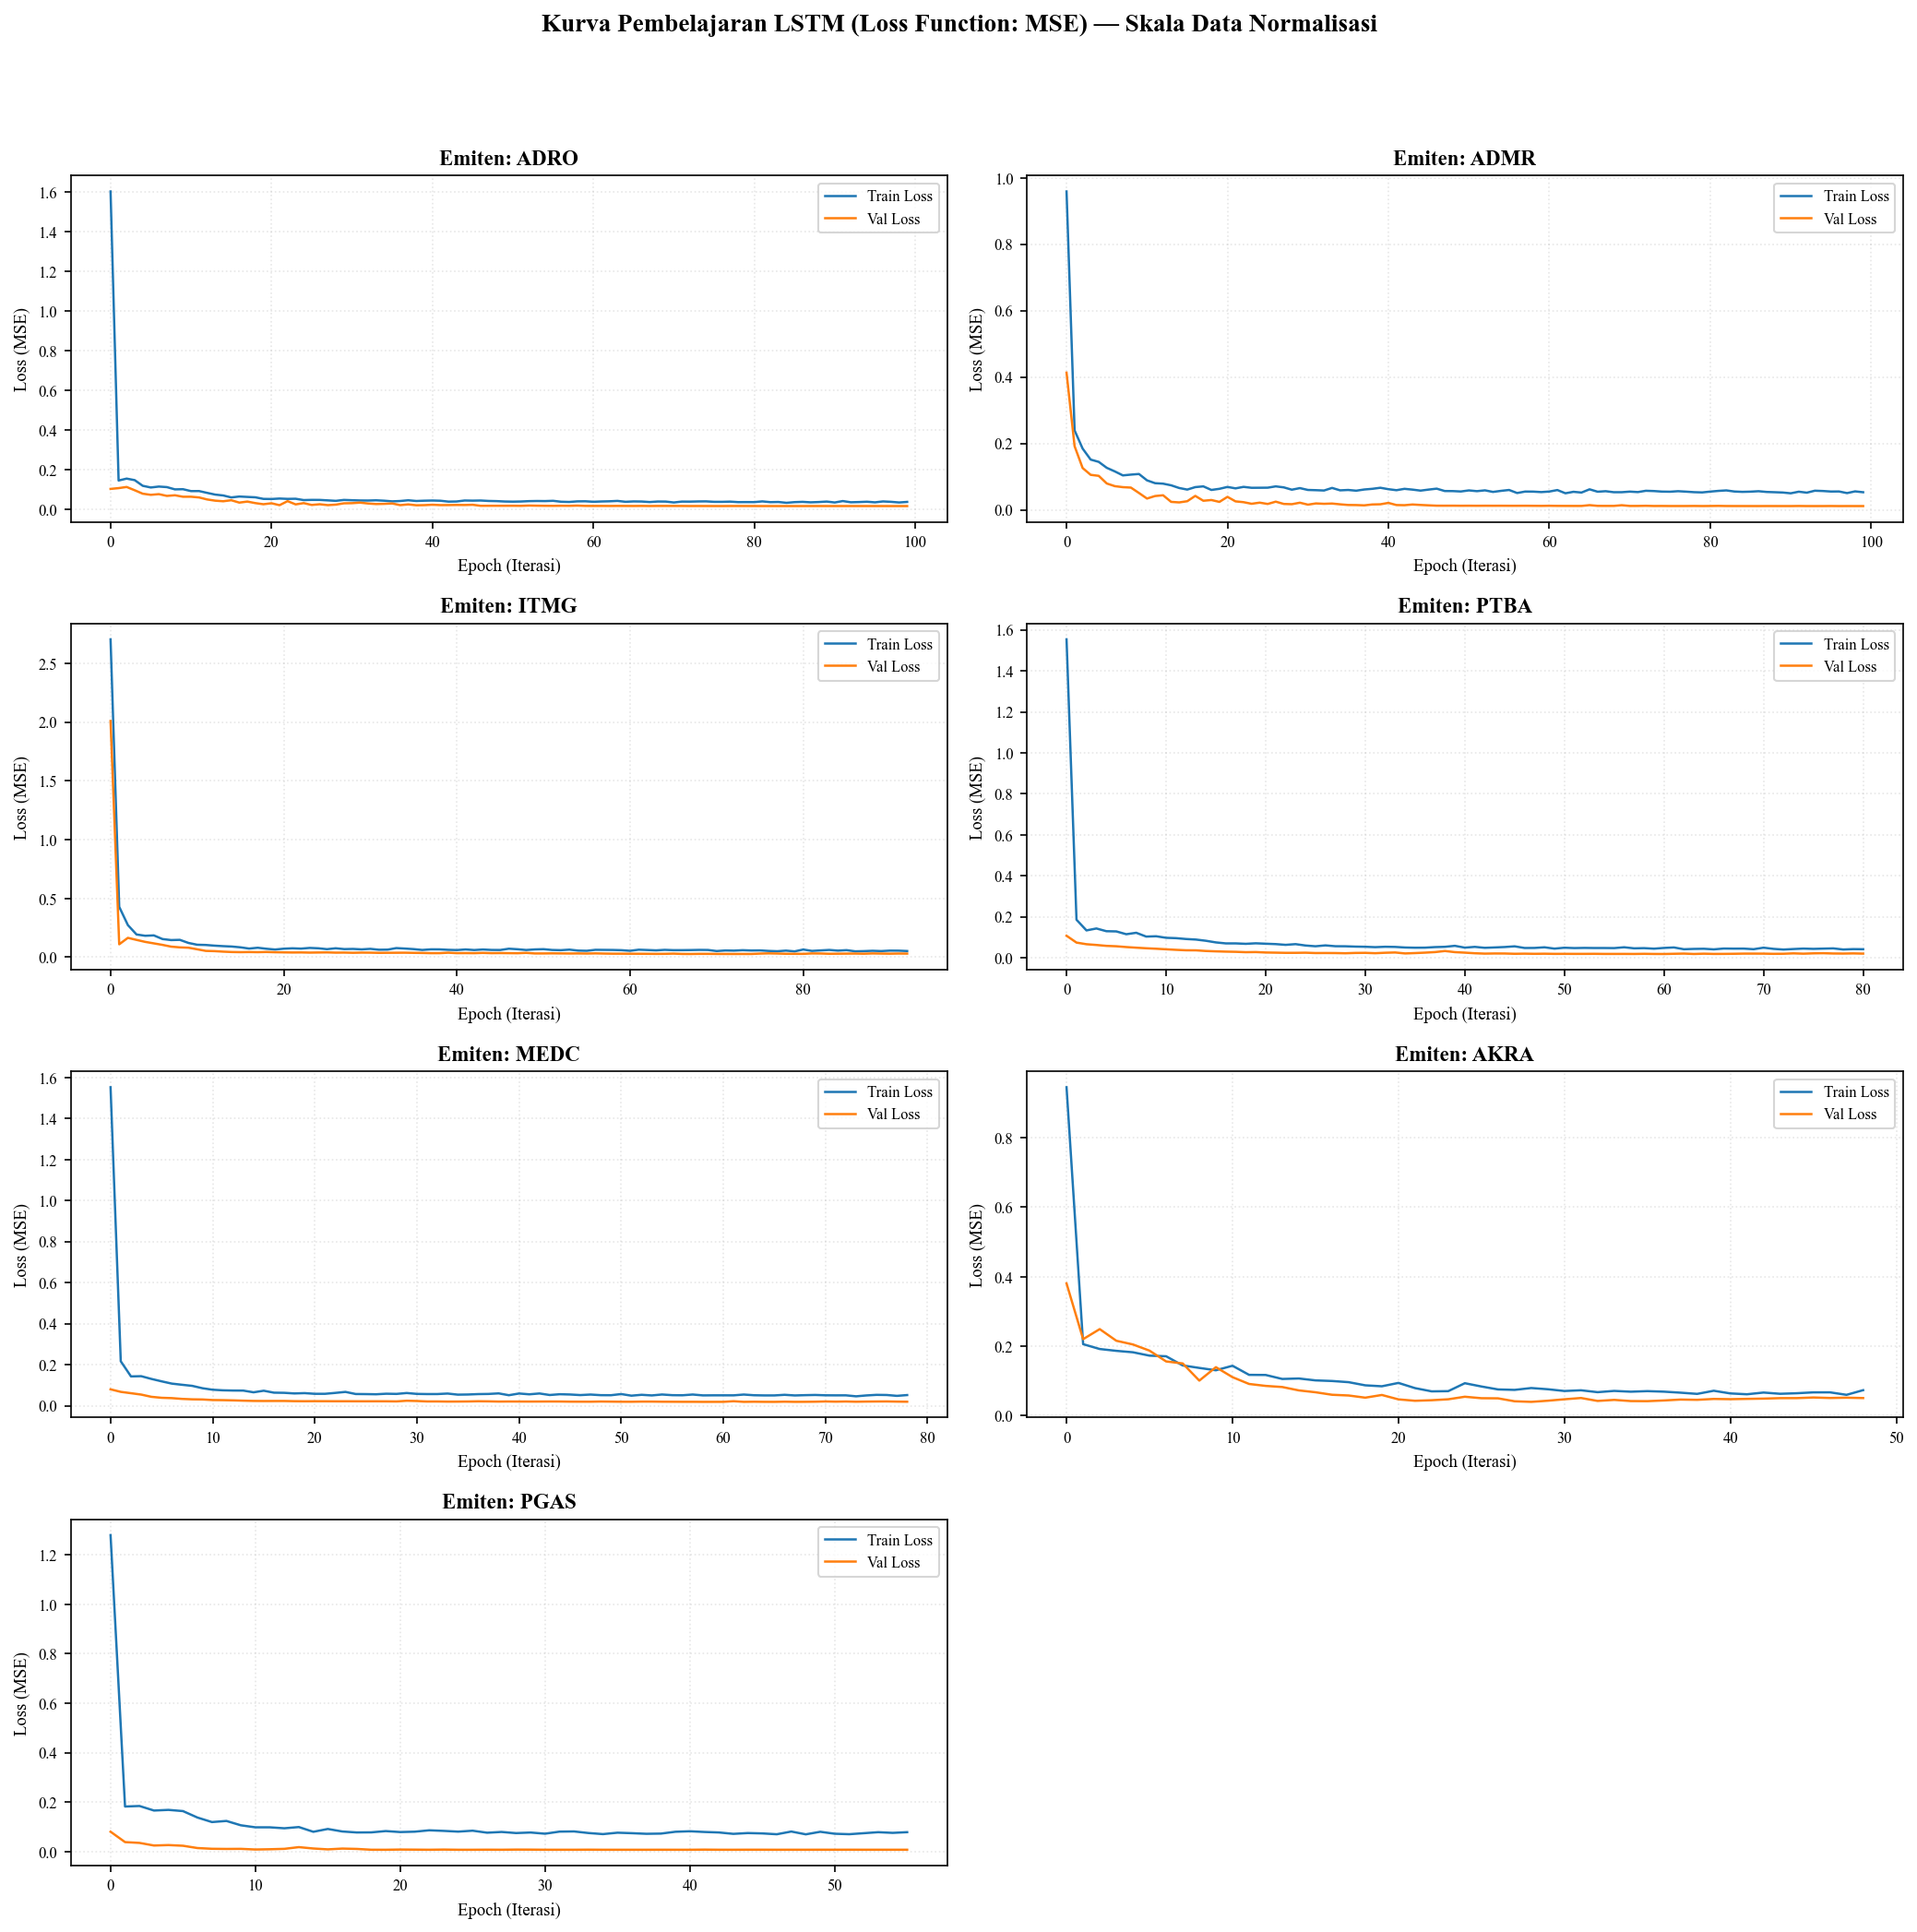

 💾 SUKSES: Grafik kurva pembelajaran berhasil dikunci!
    Lokasi File Gambar: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_lstm_learning_curve.png


In [13]:
# ==============================================================================
# CELL — VISUALISASI LEARNING CURVE LSTM (MSE LOSS EVALUATION GRID)
# ==============================================================================

# 1. Tegaskan kembali aturan gaya visualisasi standar naskah akademis (Times New Roman)
plt.rcParams.update({
    'font.family'    : 'Times New Roman',
    'font.size'      : 11,
    'axes.titlesize' : 11,
    'axes.labelsize' : 9,
    'figure.dpi'     : 150,
})

# 2. Filter emiten yang memiliki riwayat history pelatihan valid
emiten_ok = [e for e in URUTAN_EMITEN if e in dict_history]
ncol = 2
nrow = int(np.ceil(len(emiten_ok) / ncol))

# 3. Inisialisasi kanvas multi-grid
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.5 * nrow))
axes = np.array(axes).ravel()

# Judul Makro Kurva Eksperimen
fig.suptitle('Kurva Pembelajaran LSTM (Loss Function: MSE) — Skala Data Normalisasi', 
             fontweight='bold', fontsize=13, y=0.995)

# 4. Looping penggambaran grafik loss vs val_loss per emiten
for ax, emiten in zip(axes, emiten_ok):
    h = dict_history[emiten]
    
    # Plot fungsi kerugian data latih dan data validasi internal
    ax.plot(h['loss'], color='#1f77b4', linewidth=1.2, label='Train Loss')
    ax.plot(h['val_loss'], color='#ff7f0e', linewidth=1.2, linestyle='-', label='Val Loss')
    
    # Anotasi judul subplot dan pengaturan label sumbu matematika baku
    ax.set_title(f'Emiten: {emiten}', fontweight='bold')
    ax.set_xlabel('Epoch (Iterasi)')
    ax.set_ylabel('Loss (MSE)')
    
    # Konfigurasi kosmetik grid pendukung teks
    ax.legend(fontsize=8, loc='upper right')
    ax.tick_params(labelsize=8)
    ax.grid(True, alpha=0.3, linestyle=':')

# 5. Nonaktifkan panel ke-8 (Grid sisa pojok kanan bawah kosong karena total 7 emiten)
for ax in axes[len(emiten_ok):]: 
    ax.axis('off')

# Optimasi susunan agar elemen visual tidak saling bertubrukan
plt.tight_layout(rect=[0, 0, 1, 0.96])

# 6. Ekspor Berkas Gambar Resolusi Tinggi ke DIR_GAMBAR Tesis
jalur_simpan_grafik = DIR_GAMBAR / 'gambar_lstm_learning_curve.png'
plt.savefig(jalur_simpan_grafik, dpi=150, bbox_inches='tight')
plt.show()

print('=' * 85)
print(f' 💾 SUKSES: Grafik kurva pembelajaran berhasil dikunci!')
print(f'    Lokasi File Gambar: {jalur_simpan_grafik.resolve()}')
print('=' * 85)


## 📊 CELL 8 — Grafik Aktual vs Prediksi (→ Gambar 4.X)

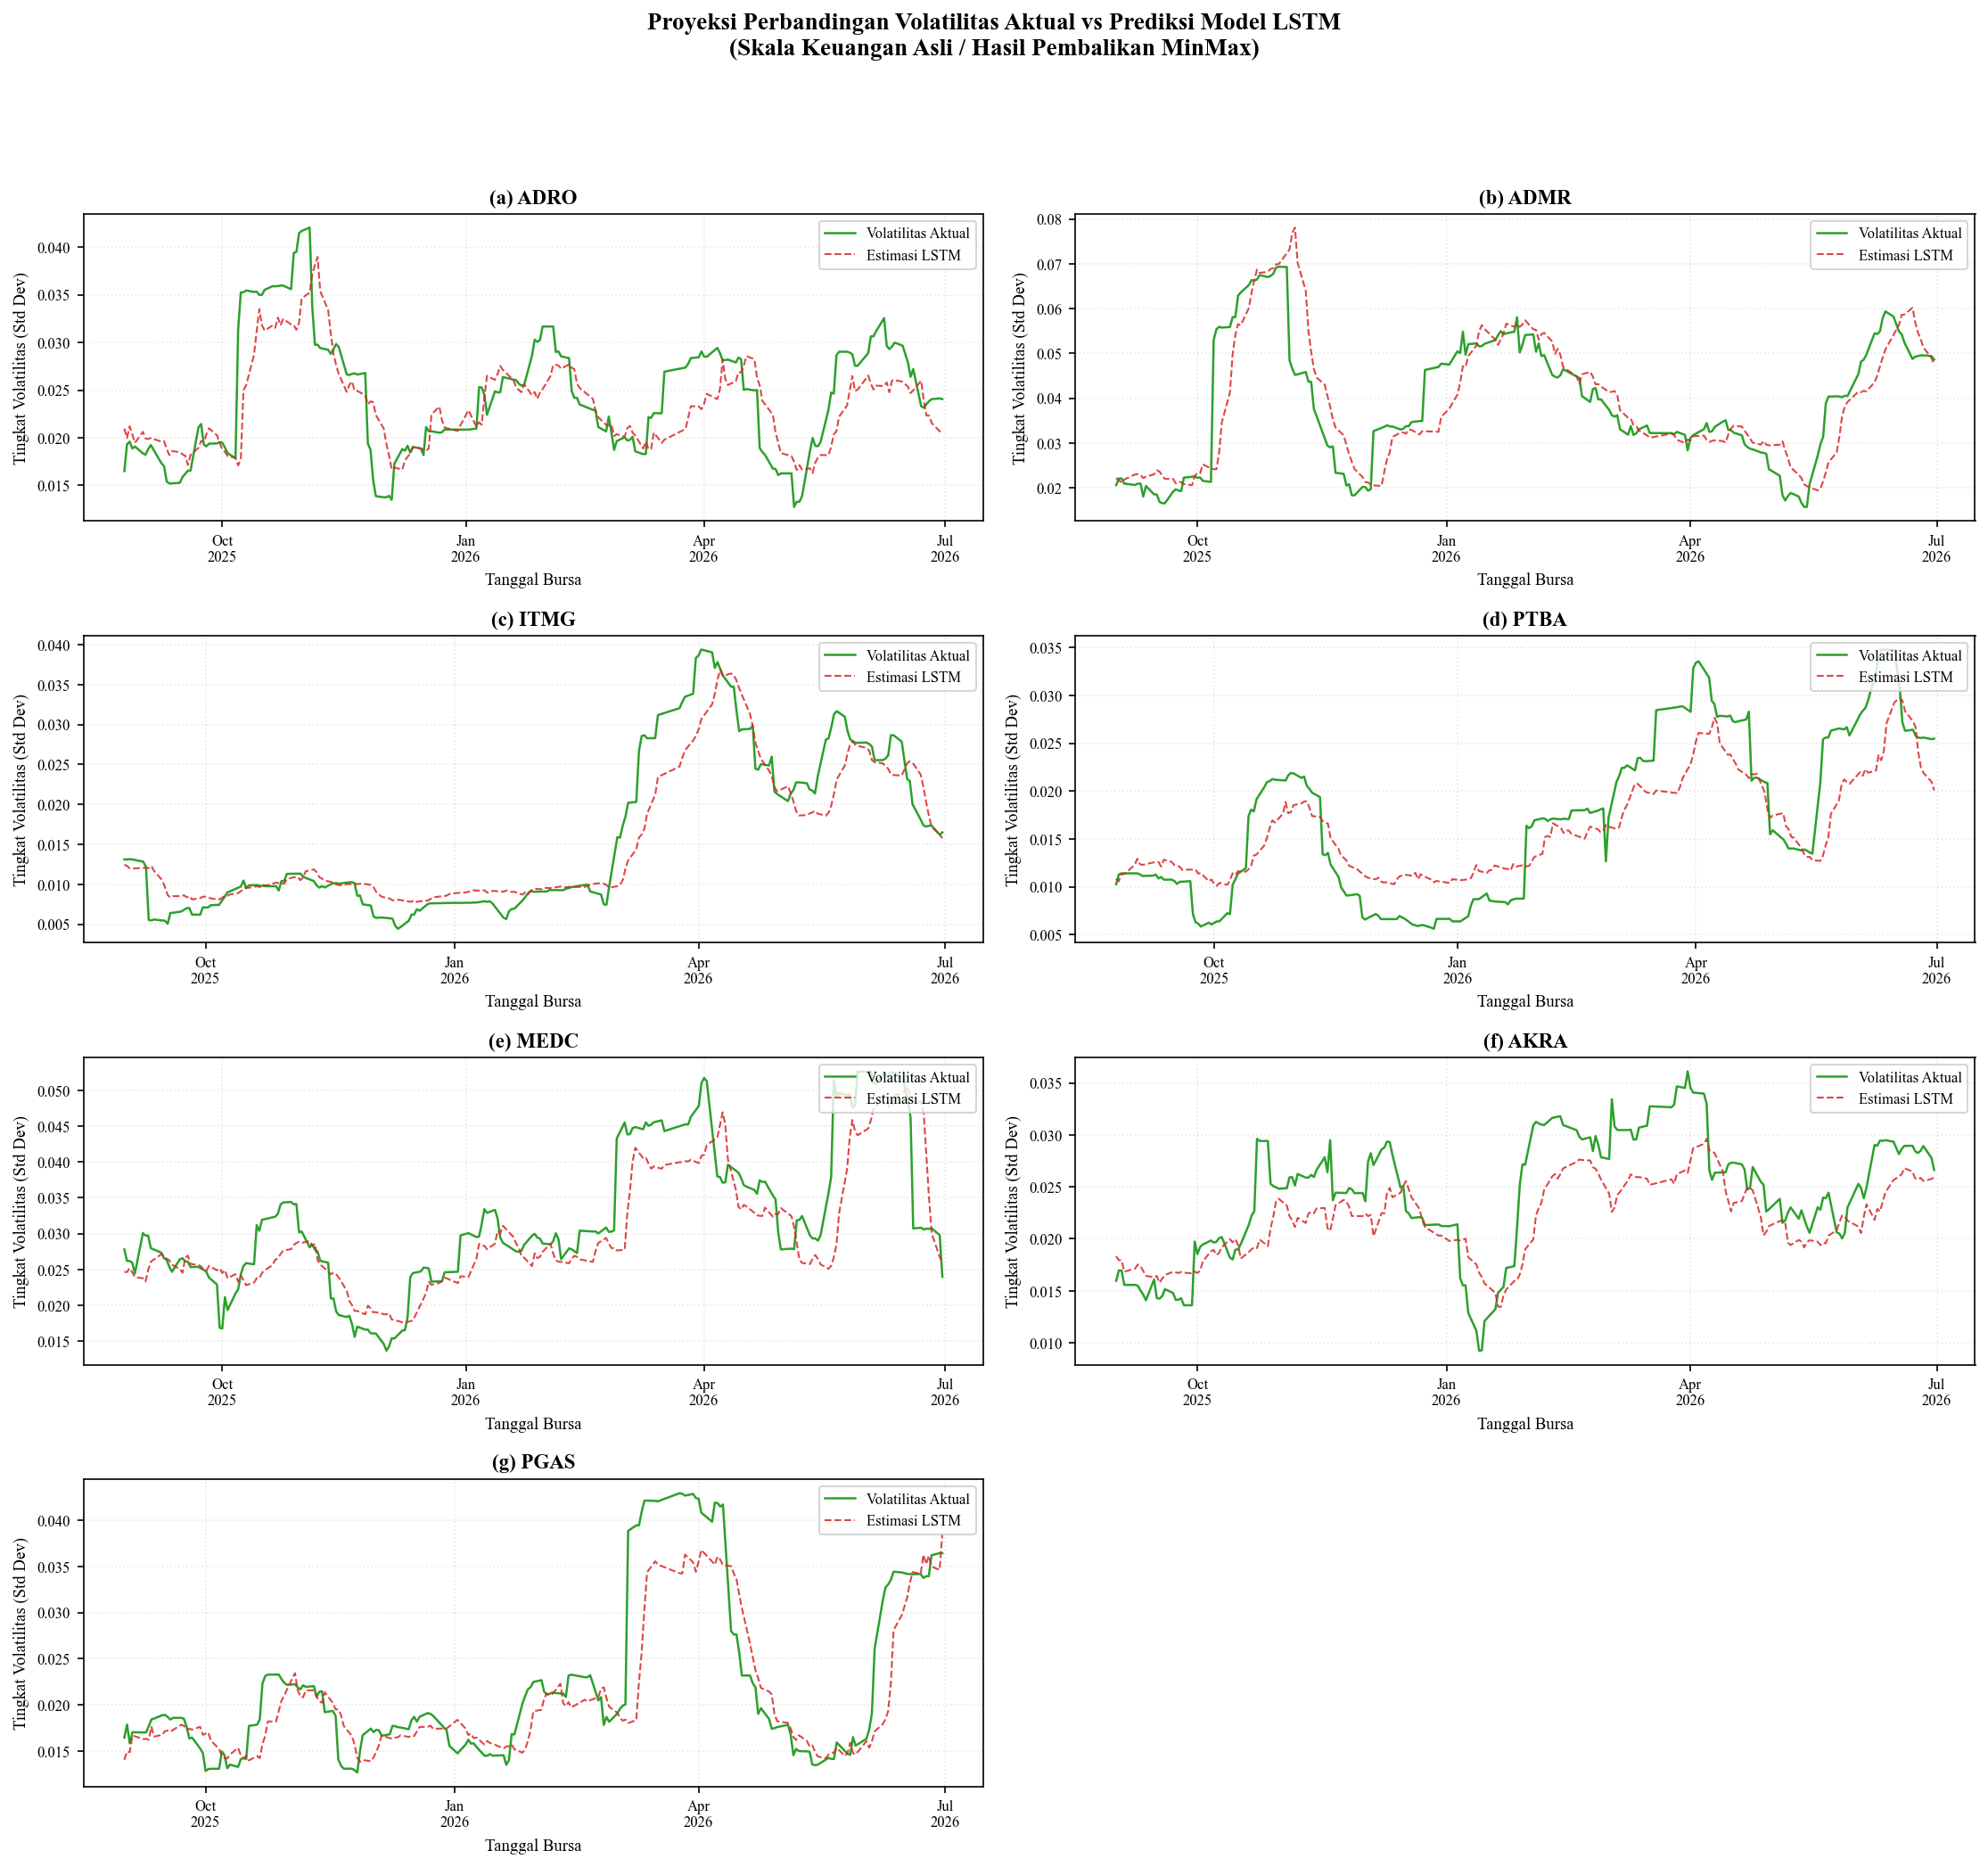

 💾 SUKSES: Grafik perbandingan nilai aktual vs prediksi LSTM berhasil dikunci!
    Lokasi File Gambar: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_lstm_prediksi_per_emiten.png


In [14]:
# ==============================================================================
# CELL — VISUALISASI PERBANDINGAN TREN VOLATILITAS AKTUAL VS PREDIKSI LSTM
# ==============================================================================

import string
import matplotlib.dates as mdates

# 1. Gaya visualisasi standar naskah akademis (Times New Roman)
plt.rcParams.update({
    'font.family'    : 'Times New Roman',
    'font.size'      : 11,
    'axes.titlesize' : 11,
    'axes.labelsize' : 9,
    'figure.dpi'     : 150,
})

# 2. Filter emiten yang punya hasil prediksi valid
emiten_ok = [e for e in URUTAN_EMITEN if e in dict_hasil_lstm]
ncol = 2
nrow = int(np.ceil(len(emiten_ok) / ncol))

# 3. Inisialisasi kanvas multi-grid
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.5 * nrow))
axes = np.array(axes).ravel()

# Judul Utama Grafik  ← [BARIS DIPERBAIKI: string suptitle sebelumnya terpotong]
fig.suptitle('Proyeksi Perbandingan Volatilitas Aktual vs Prediksi Model LSTM\n'
             '(Skala Keuangan Asli / Hasil Pembalikan MinMax)',
             fontweight='bold', fontsize=13, y=0.995)

# 4. Looping penggambaran kurva volatilitas per emiten
for i, (ax, emiten) in enumerate(zip(axes, emiten_ok)):
    d = dict_hasil_lstm[emiten].copy()

    # Pastikan kolom Date bertipe datetime
    d['Date'] = pd.to_datetime(d['Date'])

    ax.plot(d['Date'], d['Y_Aktual'], color='#2ca02c', linewidth=1.2,
            label='Volatilitas Aktual')
    # ← [BARIS DIPERBAIKI: plot prediksi sebelumnya terpotong, label & tutup kurung ditambahkan]
    ax.plot(d['Date'], d['Y_Prediksi'], color='#d62728', linewidth=1.0,
            linestyle='--', alpha=0.85, label='Estimasi LSTM')

    # ← [PERUBAHAN UTAMA: judul panel jadi (a) ADRO, (b) ADMR, dst]
    ax.set_title(f'({string.ascii_lowercase[i]}) {emiten}', fontweight='bold')
    ax.set_xlabel('Tanggal Bursa')
    ax.set_ylabel('Tingkat Volatilitas (Std Dev)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.tick_params(axis='x', labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.3, linestyle=':')

# 5. Nonaktifkan panel sisa grid kosong
for ax in axes[len(emiten_ok):]:
    ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.95])

# 6. Ekspor gambar ke DIR_GAMBAR
jalur_simpan_prediksi = DIR_GAMBAR / 'gambar_lstm_prediksi_per_emiten.png'
plt.savefig(jalur_simpan_prediksi, dpi=150, bbox_inches='tight')
plt.show()

print('=' * 85)
print(' 💾 SUKSES: Grafik perbandingan nilai aktual vs prediksi LSTM berhasil dikunci!')
print(f'    Lokasi File Gambar: {jalur_simpan_prediksi.resolve()}')
print('=' * 85)

In [15]:
from pathlib import Path
print("DIR_FINAL =", DIR_FINAL)
files = sorted(Path(DIR_FINAL).glob('*.csv'))
print("Jumlah file:", len(files))
for f in files[:10]:
    print("  -", f.name)

DIR_FINAL = e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final
Jumlah file: 33
  - berita_gabungan_semua_sumber_FINAL.csv
  - dataset_final_gabungan.csv
  - dataset_final_normalized.csv
  - dataset_gabungan_final.csv
  - dataset_gabungan_X1X2Y.csv
  - dataset_test_ADMR.csv
  - dataset_test_ADRO.csv
  - dataset_test_AKRA.csv
  - dataset_test_ITMG.csv
  - dataset_test_MEDC.csv


In [16]:
from pathlib import Path
import pandas as pd

# Cari di beberapa kandidat lokasi
kandidat_dir = []
for n in ['DIR_FINAL','DIR_PROCESSED','DIR_RAW','DIR_DATASET','ROOT']:
    if n in dir():
        kandidat_dir.append(Path(eval(n)))

# Kumpulkan semua csv, cari yang punya kolom volatilitas + per-emiten
print("Memindai CSV...\n")
for base in kandidat_dir:
    for f in base.rglob('*.csv'):
        try:
            head = pd.read_csv(f, nrows=1)
            cols = [c.lower() for c in head.columns]
            if any('vol' in c for c in cols) and any(k in c for c in cols for k in ['date','tanggal']):
                print("✅", f.relative_to(base.parent) if base.parent in f.parents else f.name)
                print("   kolom:", list(head.columns))
        except Exception:
            pass

Memindai CSV...

✅ final\dataset_final_gabungan.csv
   kolom: ['Tanggal', 'Kode_Emiten', 'Nama_Perusahaan', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Log_Return', 'Volatilitas_Return', 'RSI', 'MA_5', 'MA_10', 'MA_20', 'Stoch_%K', 'Stoch_%D', 'Skor_Sentimen', 'Jumlah_Artikel', 'Ada_Berita']
✅ final\dataset_final_normalized.csv
   kolom: ['Date', 'Emiten', 'Close', 'High', 'Low', 'Volume', 'Log_Return', 'Volatilitas', 'MA5', 'MA10', 'MA20', 'EMA12', 'EMA26', 'RSI14', 'MACD', 'MACD_Signal', 'MACD_Hist', 'BB_Upper', 'BB_Middle', 'BB_Lower', 'BB_Width', 'BB_PctB', 'Stoch_K', 'Stoch_D', 'Volume_Change', 'Volume_MA5', 'Volume_ZScore', 'Target_Volatility', 'Skor_Sentimen', 'N_Berita', 'Ada_Berita', 'Skor_Sentimen_Lag1', 'Sentiment_MA20', 'Sentiment_STD20', 'Sentiment_Min20', 'Sentiment_Max20', 'Split']
✅ final\dataset_gabungan_final.csv
   kolom: ['Date', 'Emiten', 'Close', 'High', 'Low', 'Volume', 'Log_Return', 'Volatilitas', 'MA5', 'MA10', 'MA20', 'EMA12', 'EMA26', 'RSI14', 'MA

[CEK SKALA] target latih 'Volatilitas_Target' median=0.17214 | Y_Aktual uji median=0.02419
⚠️  Skala latih & uji BERBEDA jauh → garis akan melompat di batas.
    Target latih kemungkinan masih ter-normalisasi; perlu inverse transform dulu.


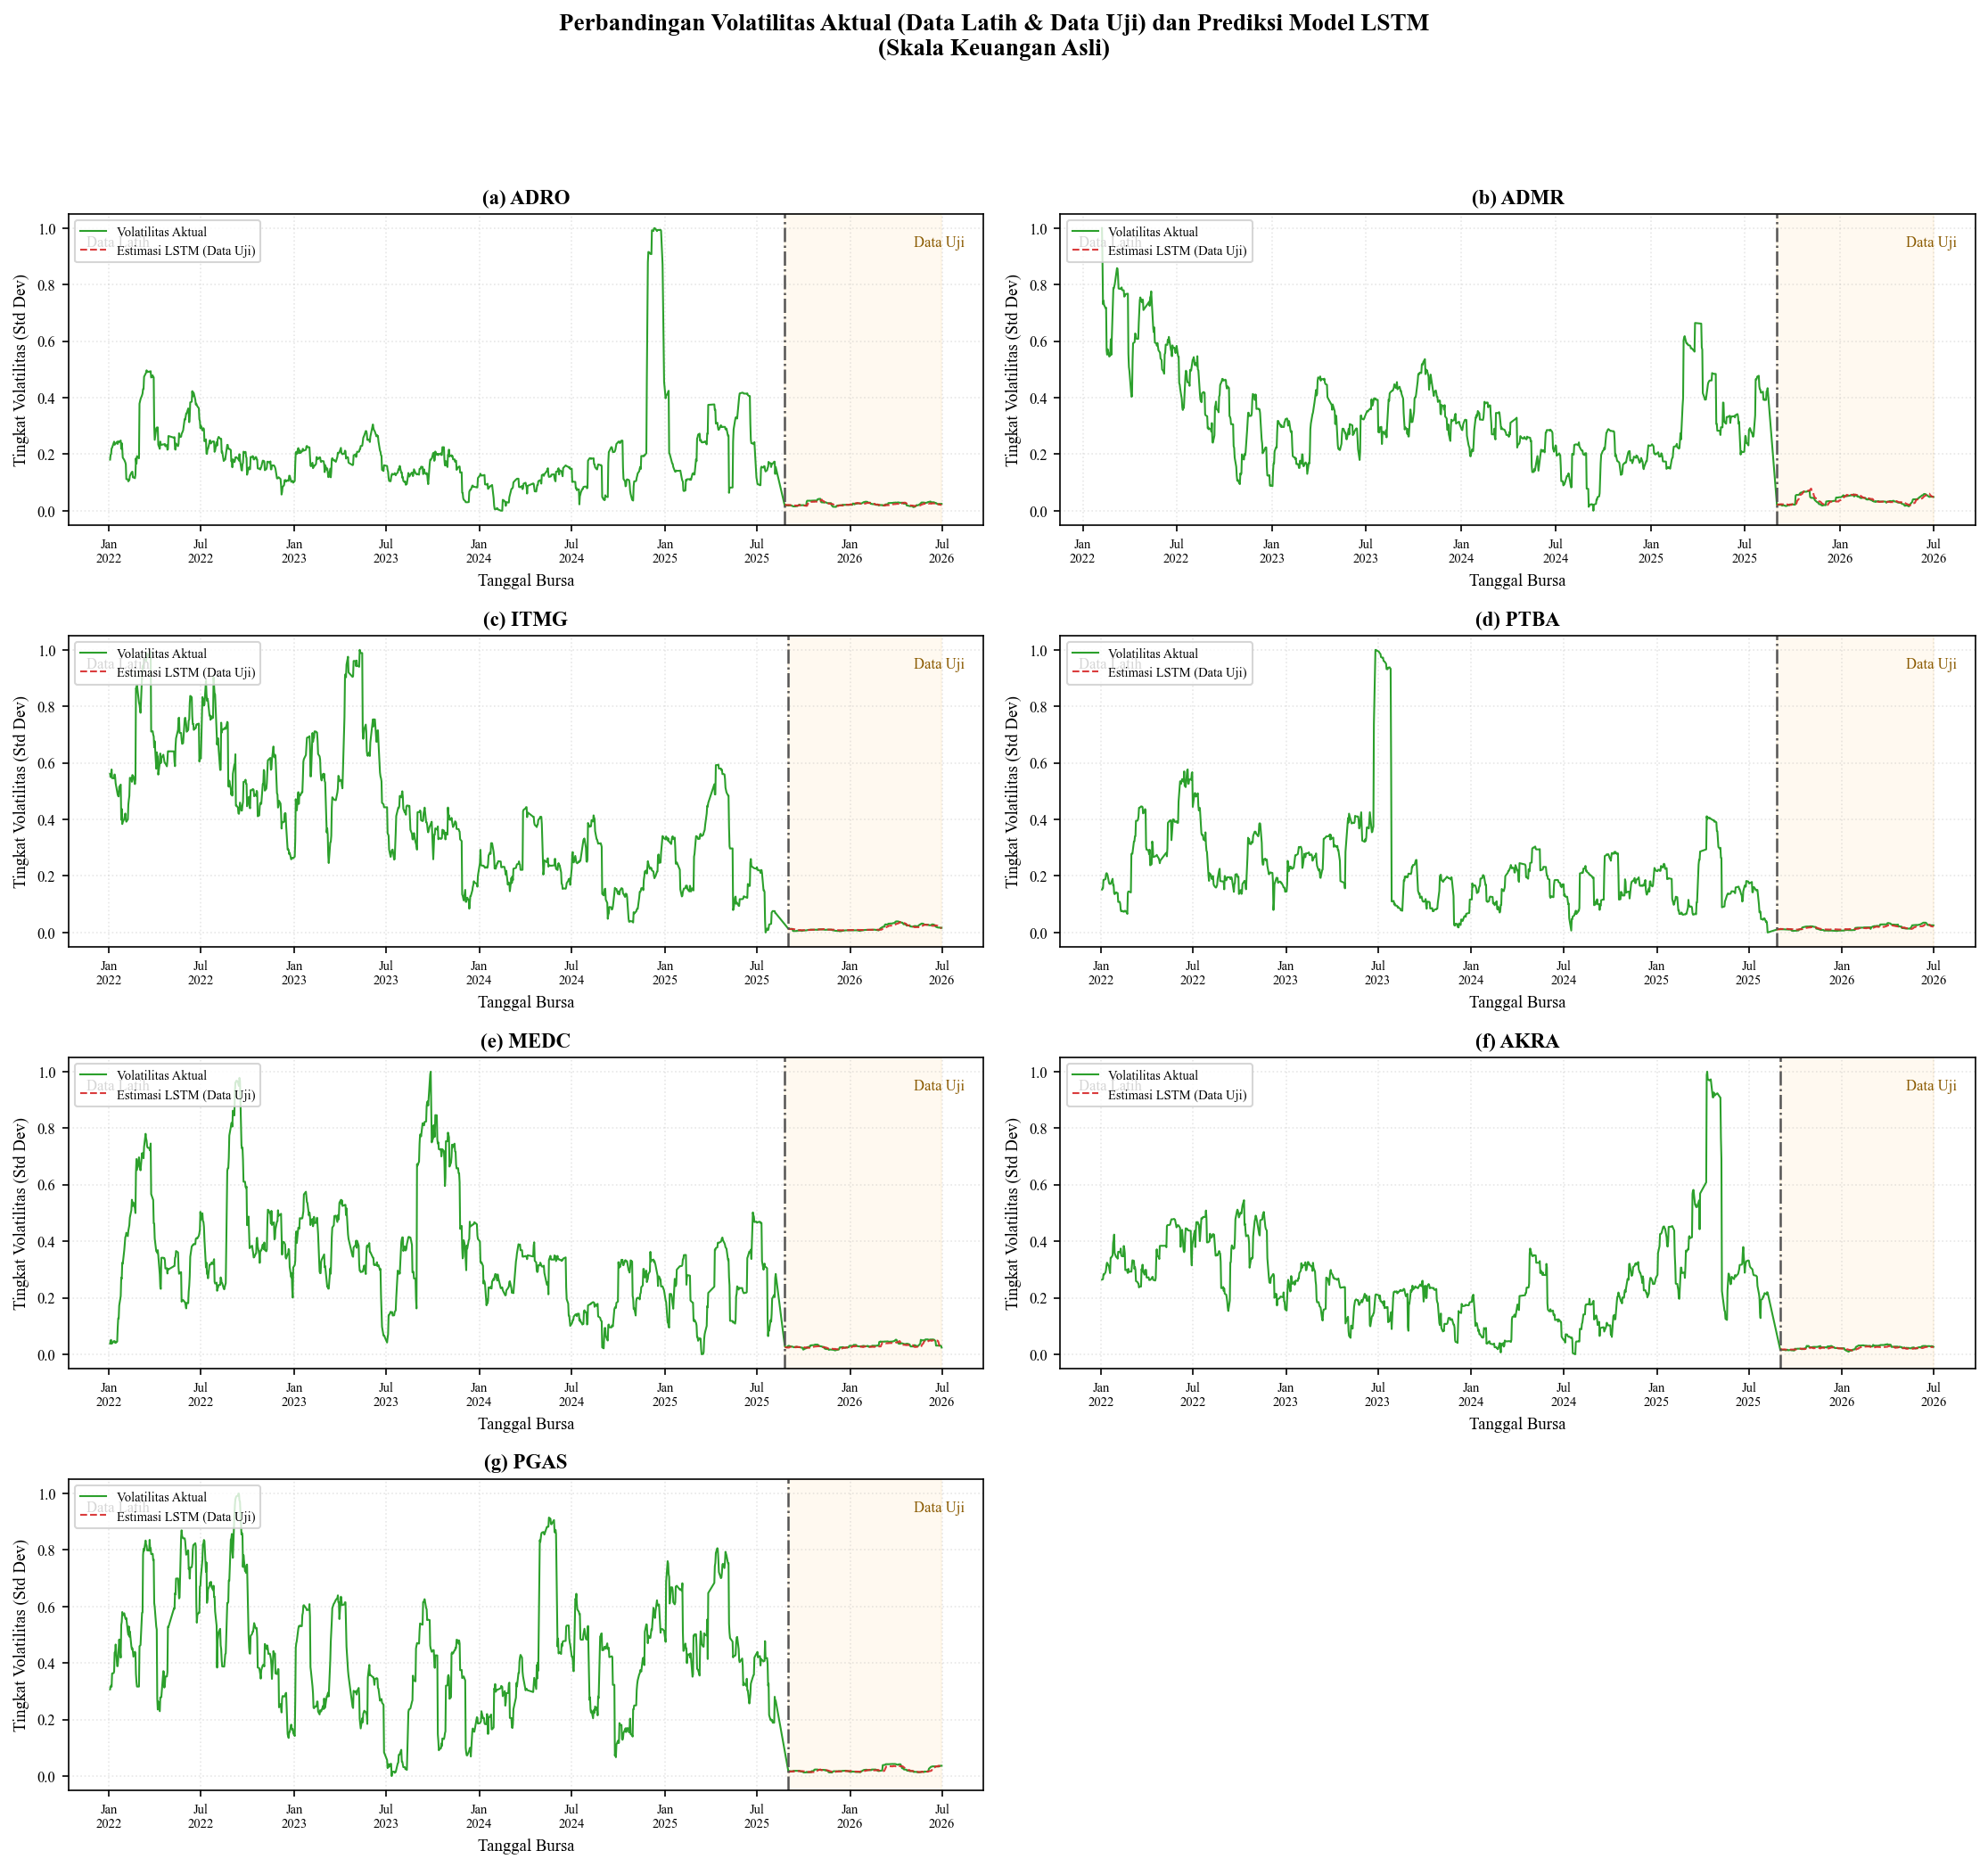

 💾 Grafik latih+uji tersimpan: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_lstm_latih_uji_per_emiten.png


In [18]:
# ==============================================================================
# CELL — VISUALISASI DATA LATIH + DATA UJI (dengan garis batas & prediksi LSTM)
# ==============================================================================
import string
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    'font.family': 'Times New Roman', 'font.size': 11,
    'axes.titlesize': 11, 'axes.labelsize': 9, 'figure.dpi': 150,
})

emiten_ok = [e for e in URUTAN_EMITEN if e in dict_hasil_lstm and e in dict_train]

# --- Deteksi kolom target (mengikuti konvensi notebook Anda) ---
def get_target_col(df):
    if 'Target_Volatility' in df.columns:
        return 'Target_Volatility'
    try:
        return KOLOM_Y
    except NameError:
        kand = [c for c in df.columns if 'target' in c.lower()]
        return kand[0] if kand else 'Vol_Lag0'

# --- DIAGNOSTIK SKALA (cek emiten pertama) ---
e0   = emiten_ok[0]
tcol = get_target_col(dict_train[e0])
med_tr = float(pd.to_numeric(dict_train[e0][tcol], errors='coerce').median())
med_te = float(pd.to_numeric(dict_hasil_lstm[e0]['Y_Aktual'], errors='coerce').median())
print(f"[CEK SKALA] target latih '{tcol}' median={med_tr:.5f} | Y_Aktual uji median={med_te:.5f}")
if med_tr > 0 and (med_te/med_tr > 3 or med_tr/med_te > 3):
    print("⚠️  Skala latih & uji BERBEDA jauh → garis akan melompat di batas.")
    print("    Target latih kemungkinan masih ter-normalisasi; perlu inverse transform dulu.")
else:
    print("✅ Skala latih & uji sebanding — garis aktual akan menyambung mulus.")

# --- Kanvas grid ---
ncol = 2
nrow = int(np.ceil(len(emiten_ok) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.5 * nrow))
axes = np.array(axes).ravel()

fig.suptitle('Perbandingan Volatilitas Aktual (Data Latih & Data Uji) '
             'dan Prediksi Model LSTM\n(Skala Keuangan Asli)',
             fontweight='bold', fontsize=13, y=0.995)

for i, (ax, emiten) in enumerate(zip(axes, emiten_ok)):
    tr = dict_train[emiten].copy()
    te = dict_hasil_lstm[emiten].copy()
    tr['Date'] = pd.to_datetime(tr['Date'])
    te['Date'] = pd.to_datetime(te['Date'])
    tcol = get_target_col(tr)

    split_date = te['Date'].min()

    # Garis AKTUAL menyambung (latih + uji) dalam satu seri
    aktual = pd.concat([
        tr[['Date', tcol]].rename(columns={tcol: 'v'}),
        te[['Date']].assign(v=te['Y_Aktual'].values)
    ]).sort_values('Date')

    ax.plot(aktual['Date'], aktual['v'], color='#2ca02c', lw=1.0,
            label='Volatilitas Aktual')
    # Garis PREDIKSI hanya di wilayah data uji
    ax.plot(te['Date'], te['Y_Prediksi'], color='#d62728', lw=1.0,
            linestyle='--', alpha=0.9, label='Estimasi LSTM (Data Uji)')

    # Penanda batas latih/uji
    ax.axvline(split_date, color='#555555', lw=1.2, linestyle='-.')
    ax.axvspan(split_date, aktual['Date'].max(), color='orange', alpha=0.06)

    # Anotasi wilayah
    ax.text(0.02, 0.93, 'Data Latih', transform=ax.transAxes,
            fontsize=8, ha='left', va='top', color='#333333')
    ax.text(0.98, 0.93, 'Data Uji', transform=ax.transAxes,
            fontsize=8, ha='right', va='top', color='#8a5a00')

    ax.set_title(f'({string.ascii_lowercase[i]}) {emiten}', fontweight='bold')
    ax.set_xlabel('Tanggal Bursa')
    ax.set_ylabel('Tingkat Volatilitas (Std Dev)')

    # Rentang panjang (2022–2026) → tick per 6 bulan
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.tick_params(axis='x', labelsize=7)
    ax.tick_params(axis='y', labelsize=8)
    ax.legend(fontsize=7, loc='upper left')
    ax.grid(True, alpha=0.3, linestyle=':')

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.95])
jalur = DIR_GAMBAR / 'gambar_lstm_latih_uji_per_emiten.png'
plt.savefig(jalur, dpi=150, bbox_inches='tight')
plt.show()
print('=' * 85)
print(f' 💾 Grafik latih+uji tersimpan: {jalur.resolve()}')
print('=' * 85)

Rekonstruksi skala (korelasi harus ≈ 1.000000):
  ADRO: a=0.081274, b=0.009189, korelasi=1.000000, n=205
  ADMR: a=0.070075, b=0.009526, korelasi=1.000000, n=200
  ITMG: a=0.033632, b=0.005098, korelasi=1.000000, n=200
  PTBA: a=0.054986, b=0.007085, korelasi=1.000000, n=205
  MEDC: a=0.051189, b=0.011549, korelasi=1.000000, n=205
  AKRA: a=0.056688, b=0.009007, korelasi=1.000000, n=200
  PGAS: a=0.026613, b=0.007216, korelasi=1.000000, n=200

[CEK SKALA] target latih median=0.02318 | Y_Aktual uji median=0.02419
✅ Skala latih & uji sebanding — garis aktual akan menyambung mulus.


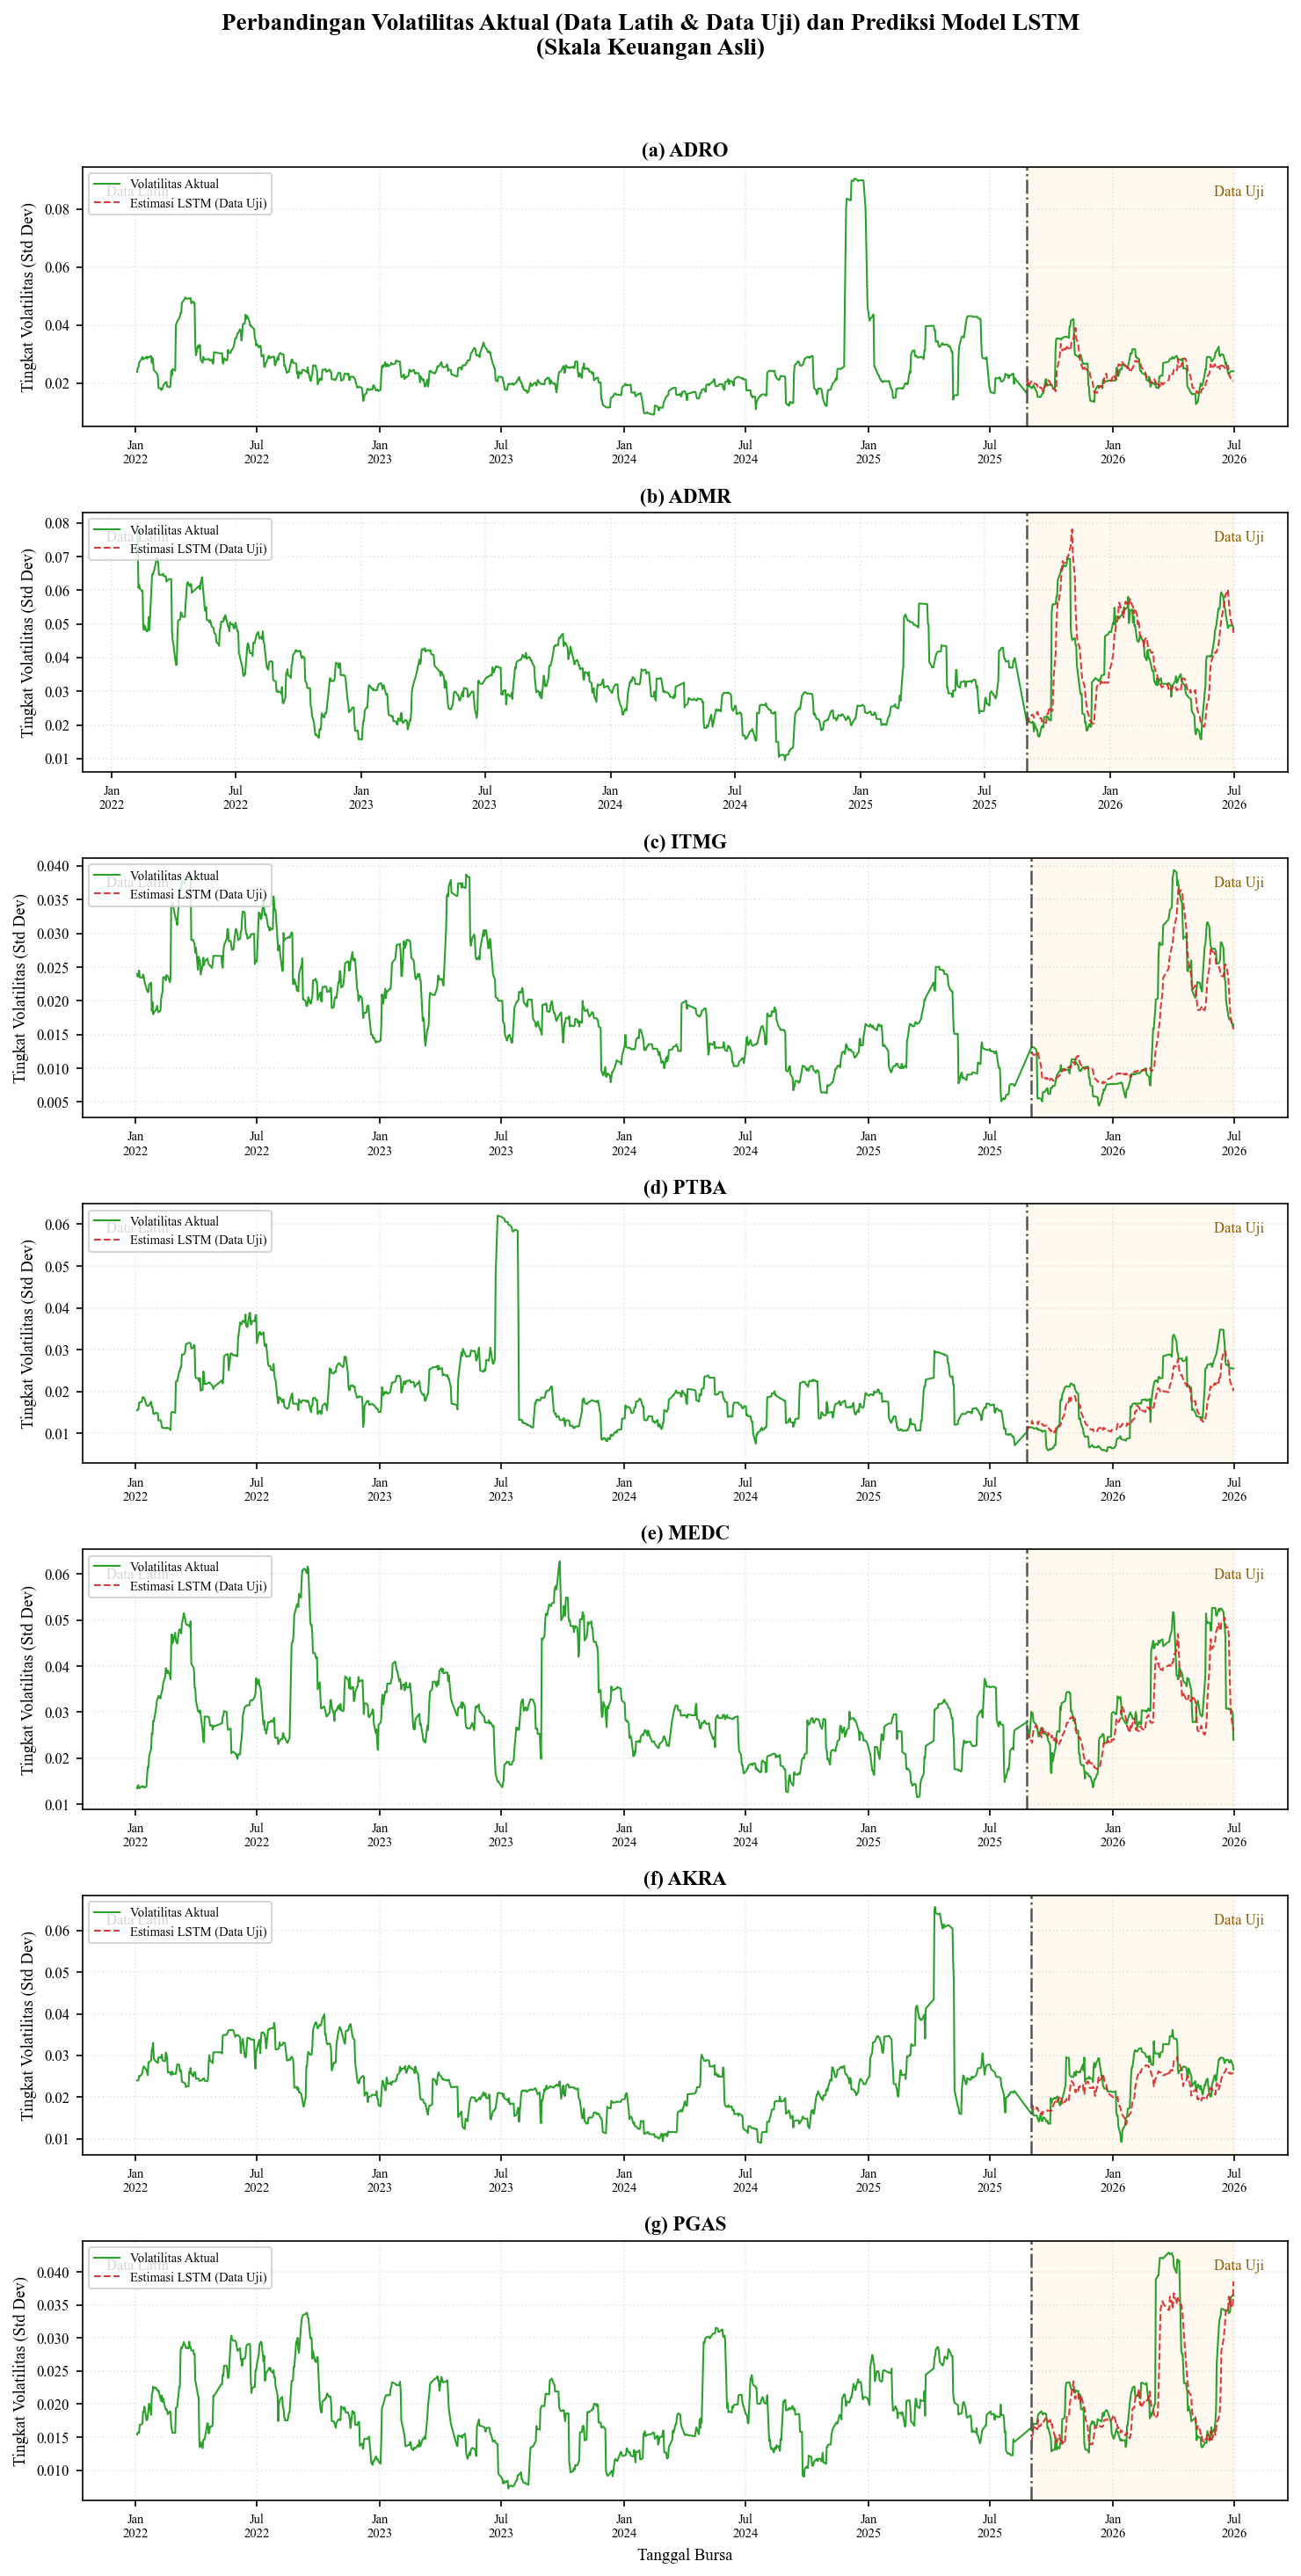

 💾 Grafik latih+uji tersimpan: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_lstm_latih_uji_per_emiten.png


In [27]:
# ==============================================================================
# CELL — VISUALISASI DATA LATIH + DATA UJI (dengan garis batas & prediksi LSTM)
#        Layout 1 kolom (susun ke bawah), skala asli
# ==============================================================================
import string
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    'font.family': 'Times New Roman', 'font.size': 11,
    'axes.titlesize': 11, 'axes.labelsize': 9, 'figure.dpi': 150,
})

emiten_ok = [e for e in URUTAN_EMITEN
             if e in dict_hasil_lstm and e in dict_train and e in dict_test]


# --- Deteksi kolom target (mengikuti konvensi notebook Anda) ---
def get_target_col(df):
    if 'Target_Volatility' in df.columns:
        return 'Target_Volatility'
    try:
        return KOLOM_Y
    except NameError:
        kand = [c for c in df.columns if 'target' in c.lower()]
        return kand[0] if kand else 'Vol_Lag0'


# --- KEMBALIKAN TARGET DATA LATIH KE SKALA ASLI (rekonstruksi Min-Max) ---
dict_train_asli = {}
print('Rekonstruksi skala (korelasi harus ≈ 1.000000):')
for e in emiten_ok:
    tcol = get_target_col(dict_train[e])

    # Pasangkan target uji ternormalisasi (dict_test) dengan nilai asli (dict_hasil_lstm)
    t_scaled = dict_test[e][['Date', tcol]].copy()
    t_asli   = dict_hasil_lstm[e][['Date', 'Y_Aktual']].copy()
    t_scaled['Date'] = pd.to_datetime(t_scaled['Date'])
    t_asli['Date']   = pd.to_datetime(t_asli['Date'])
    pasangan = t_scaled.merge(t_asli, on='Date').dropna()

    # asli = a * ternormalisasi + b
    a, b = np.polyfit(pasangan[tcol], pasangan['Y_Aktual'], 1)
    r = np.corrcoef(pasangan[tcol], pasangan['Y_Aktual'])[0, 1]
    print(f'  {e}: a={a:.6f}, b={b:.6f}, korelasi={r:.6f}, n={len(pasangan)}')

    tr = dict_train[e].copy()
    tr[tcol] = a * tr[tcol] + b
    dict_train_asli[e] = tr


# --- DIAGNOSTIK SKALA (cek emiten pertama) ---
e0   = emiten_ok[0]
tcol = get_target_col(dict_train_asli[e0])
med_tr = float(pd.to_numeric(dict_train_asli[e0][tcol], errors='coerce').median())
med_te = float(pd.to_numeric(dict_hasil_lstm[e0]['Y_Aktual'], errors='coerce').median())
print(f"\n[CEK SKALA] target latih median={med_tr:.5f} | Y_Aktual uji median={med_te:.5f}")
if med_tr > 0 and (med_te / med_tr > 3 or med_tr / med_te > 3):
    print("⚠️  Skala latih & uji masih BERBEDA jauh.")
else:
    print("✅ Skala latih & uji sebanding — garis aktual akan menyambung mulus.")


# --- Kanvas: 1 kolom, susun ke bawah ---
ncol = 1
nrow = len(emiten_ok)
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 2.8 * nrow))
axes = np.array(axes).ravel()

fig.suptitle('Perbandingan Volatilitas Aktual (Data Latih & Data Uji) '
             'dan Prediksi Model LSTM\n(Skala Keuangan Asli)',
             fontweight='bold', fontsize=13, y=0.995)

for i, (ax, emiten) in enumerate(zip(axes, emiten_ok)):
    tr = dict_train_asli[emiten].copy()
    te = dict_hasil_lstm[emiten].copy()
    tr['Date'] = pd.to_datetime(tr['Date'])
    te['Date'] = pd.to_datetime(te['Date'])
    tcol = get_target_col(tr)

    split_date = te['Date'].min()

    # Garis AKTUAL menyambung (latih + uji) dalam satu seri
    aktual = pd.concat([
        tr[['Date', tcol]].rename(columns={tcol: 'v'}),
        te[['Date']].assign(v=te['Y_Aktual'].values)
    ]).sort_values('Date')

    ax.plot(aktual['Date'], aktual['v'], color='#2ca02c', lw=1.0,
            label='Volatilitas Aktual')
    # Garis PREDIKSI hanya di wilayah data uji
    ax.plot(te['Date'], te['Y_Prediksi'], color='#d62728', lw=1.0,
            linestyle='--', alpha=0.9, label='Estimasi LSTM (Data Uji)')

    # Penanda batas latih/uji
    ax.axvline(split_date, color='#555555', lw=1.2, linestyle='-.')
    ax.axvspan(split_date, aktual['Date'].max(), color='orange', alpha=0.06)

    # Anotasi wilayah
    ax.text(0.02, 0.93, 'Data Latih', transform=ax.transAxes,
            fontsize=8, ha='left', va='top', color='#333333')
    ax.text(0.98, 0.93, 'Data Uji', transform=ax.transAxes,
            fontsize=8, ha='right', va='top', color='#8a5a00')

    ax.set_title(f'({string.ascii_lowercase[i]}) {emiten}', fontweight='bold')

    # Label sumbu X hanya di panel paling bawah
    if i == len(emiten_ok) - 1:
        ax.set_xlabel('Tanggal Bursa')
    else:
        ax.set_xlabel('')
    ax.set_ylabel('Tingkat Volatilitas (Std Dev)')

    # Rentang panjang (2022–2026) → tick per 6 bulan
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.tick_params(axis='x', labelsize=7)
    ax.tick_params(axis='y', labelsize=8)
    ax.legend(fontsize=7, loc='upper left')
    ax.grid(True, alpha=0.3, linestyle=':')

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.98])
jalur = DIR_GAMBAR / 'gambar_lstm_latih_uji_per_emiten.png'
plt.savefig(jalur, dpi=300, bbox_inches='tight')
plt.show()
print('=' * 85)
print(f' 💾 Grafik latih+uji tersimpan: {jalur.resolve()}')
print('=' * 85)

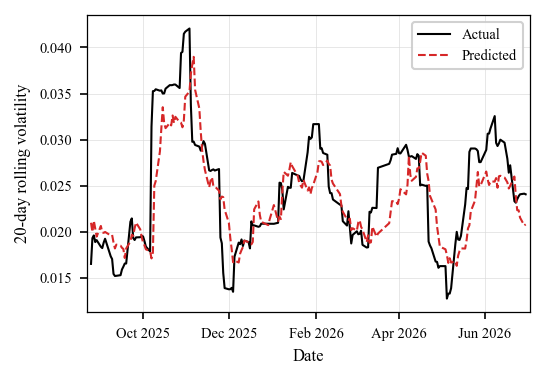

💾 gambar prediksi LSTM ADRO tersimpan


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

EMITEN = 'ADRO'

plt.rcParams.update({
    'font.family'     : 'Times New Roman',
    'font.size'       : 8,
    'axes.labelsize'  : 8,
    'xtick.labelsize' : 7,
    'ytick.labelsize' : 7,
    'legend.fontsize' : 7,
    'axes.linewidth'  : 0.6,
    'pdf.fonttype'    : 42,
    'ps.fonttype'     : 42,
})

d = dict_hasil_lstm[EMITEN].copy()
d['Date'] = pd.to_datetime(d['Date'])
d = d.sort_values('Date')

fig, ax = plt.subplots(figsize=(3.5, 2.4))

ax.plot(d['Date'], d['Y_Aktual'],   color='black',   lw=1.0, label='Actual')
ax.plot(d['Date'], d['Y_Prediksi'], color='#d62728', lw=1.0, ls='--', label='Predicted')

ax.set_xlabel('Date')
ax.set_ylabel('20-day rolling volatility')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.margins(x=0.01)
ax.grid(True, linewidth=0.3, color='0.85')
ax.legend(loc='best', frameon=True, framealpha=0.9, edgecolor='0.8', handlelength=2.2)

fig.tight_layout(pad=0.3)
fig.savefig(DIR_GAMBAR / f'fig_actual_vs_predicted_lstm_{EMITEN}.pdf', bbox_inches='tight')
fig.savefig(DIR_GAMBAR / f'fig_actual_vs_predicted_lstm_{EMITEN}.png', dpi=300, bbox_inches='tight')
plt.show()
print('💾 gambar prediksi LSTM ADRO tersimpan')

ADRO: 100 epoch | val_loss terendah = 0.01824 pada epoch 98


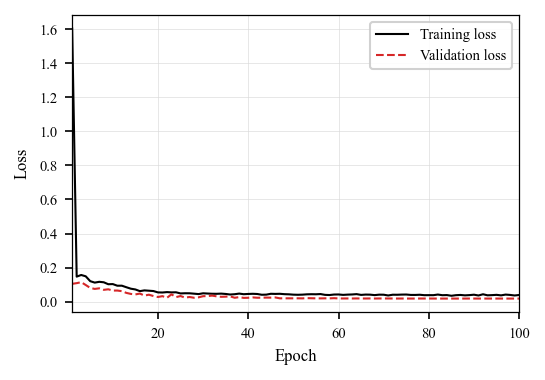

💾 gambar loss LSTM ADRO tersimpan


In [36]:
import numpy as np
import matplotlib.pyplot as plt

EMITEN = 'ADRO'

plt.rcParams.update({
    'font.family'     : 'Times New Roman',
    'font.size'       : 8,
    'axes.labelsize'  : 8,
    'xtick.labelsize' : 7,
    'ytick.labelsize' : 7,
    'legend.fontsize' : 7,
    'axes.linewidth'  : 0.6,
    'pdf.fonttype'    : 42,
    'ps.fonttype'     : 42,
})

h = dict_history[EMITEN]
h = h.history if hasattr(h, 'history') else h

train_loss = np.array(h['loss'])
val_loss   = np.array(h['val_loss'])
epoch      = np.arange(1, len(train_loss) + 1)
best_ep    = int(np.argmin(val_loss)) + 1

print(f'{EMITEN}: {len(epoch)} epoch | val_loss terendah = {val_loss.min():.5f} pada epoch {best_ep}')

fig, ax = plt.subplots(figsize=(3.5, 2.4))

ax.plot(epoch, train_loss, color='black', lw=1.0, label='Training loss')
ax.plot(epoch, val_loss, color='#d62728', lw=1.0, ls='--', label='Validation loss')

ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_xlim(1, len(epoch))
ax.grid(True, linewidth=0.3, color='0.85')
ax.legend(
    loc='upper right',
    frameon=True,
    framealpha=0.9,
    edgecolor='0.8',
    handlelength=2.2
)

fig.tight_layout(pad=0.3)
fig.savefig(DIR_GAMBAR / f'fig_loss_lstm_{EMITEN}.pdf', bbox_inches='tight')
fig.savefig(DIR_GAMBAR / f'fig_loss_lstm_{EMITEN}.png', dpi=300, bbox_inches='tight')
plt.show()

print('💾 gambar loss LSTM ADRO tersimpan')

## 💾 CELL 9 — Simpan Hasil Prediksi

In [20]:
df_all = pd.concat(dict_hasil_lstm.values(), ignore_index=True)
df_all.to_csv(DIR_TABEL / 'hasil_prediksi_lstm.csv', encoding='utf-8-sig', index=False)
print('='*70); print('✅ MODEL LSTM SELESAI')
print(f'  Hasil prediksi : hasil_prediksi_lstm.csv ({len(df_all):,} baris)')
print(f'  Model .keras   : {DIR_MODEL}')
print('  → Lanjut: jalankan EVALUASI_perbandingan.ipynb utk jawab RM-3')
print('='*70)

✅ MODEL LSTM SELESAI
  Hasil prediksi : hasil_prediksi_lstm.csv (1,415 baris)
  Model .keras   : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\04_model\lstm
  → Lanjut: jalankan EVALUASI_perbandingan.ipynb utk jawab RM-3
